# 미션 3_타이타닉 생존 예측

승객 **891명**의 정보로 생존 여부(`Survived`)를 맞히는 **이진 분류**. 탐색적 분석 → 피처 엔지니어링 → 모델 비교 → 튜닝 · 앙상블 → 최종 평가까지 **데이터 누수 없이** 연결.

| 단계 | 내용 |
| :-- | :-- |
| **0. 준비** | 라이브러리 · 그래프 설정, 데이터 불러오기, 최종 평가용 20% 분리, 결측치 처리 방침 |
| **1. 피처 엔지니어링 · 탐색적 분석** | 호칭 · 가족 규모 · 객실 정보 추출, 집단별 생존율(표본 수 함께 표시), 통계 검정 |
| **2. 전처리 · 기본 모델** | 호칭 × 등급 나이 대치 Pipeline, 가족 변수 표현 비교, 스케일러 비교, 기본 모델 4종 |
| **3. 튜닝 · 앙상블** | 6개 모델 GridSearchCV + **중첩 교차검증**, 부스팅 과적합, Soft Voting · Stacking |
| **4. 최종 평가** | 1-SE 규칙으로 모델 선택 → 최종 평가 데이터에서 한 번 확인, 중요도 · 오류 분석 |
| **5. 마무리** | 최종 결과, 핵심 결과, 한계와 다음 단계, 최종 요약표 |

**단계별 구성**: 한글 요약 → 실행 흐름 → 코드(이유 주석) → 실행 결과 → 결과 해설 → 소속별 최종 요약표

## 🎯 학습 목표

이 미션을 마치면 다음을 직접 할 수 있어야 함

1. 모델을 고르기 전에 **최종 평가 데이터를 먼저 떼어 두고**, 한 번만 사용한다
2. 이름 · 가족 · 객실 정보에서 정답을 쓰지 않는 파생 변수를 만든다
3. 결측 대치 · 스케일링을 **Pipeline 안에 넣어** 교차검증 중 누수를 막는다
4. 튜닝 점수의 낙관 편향을 **중첩 교차검증**으로 걷어내고, 1-SE 규칙으로 단순한 모델을 고른다
5. 앙상블이 실제로 다른 승객을 맞히는지, 모델이 어떤 승객을 틀리는지 오류로 확인한다

## 🧭 활용처

- **고객 이탈 · 대출 승인 · 질병 진단**: 표 데이터 이진 분류에서 누수 없는 평가 절차 그대로 사용
- **모델 선정 보고**: "튜닝 점수가 높다"가 아니라 중첩 CV · 표준오차로 근거를 제시해야 하는 상황
- **피처 엔지니어링**: 문자열(이름 · 객실 번호)에서 의미 있는 범주를 꺼내는 일반적인 방법

## 핵심 결과

- **최종 모델**: 로지스틱 회귀. 중첩 CV 정확도 **0.827** → 최종 평가 정확도 **0.838** · ROC-AUC 0.870
- **생존 요인**: 호칭 · 성별이 가장 강한 신호. 여성 74% vs 남성 19%, 1등급 여성 97% vs 3등급 남성 13%
- **복잡한 모델 ≠ 더 좋은 모델**: 랜덤 포레스트 · XGBoost는 튜닝 CV 0.84 → 중첩 CV 0.82대로 하락, Stacking(0.831)과의 차이도 표준오차 안

### 데이터 구성

- **목표 변수**: `Survived` (1 = 생존)
- **승객 정보**: `PassengerId`, `Name`(호칭 포함), `Sex`, `Age`
- **가족**: `SibSp`(형제자매 · 배우자 수), `Parch`(부모 · 자녀 수)
- **탑승 정보**: `Pclass`(객실 등급 1~3), `Ticket`, `Fare`(운임), `Cabin`(객실 번호), `Embarked`(탑승 항구 C · Q · S)

---
## 0. 준비

### 0-1. 환경 설정과 데이터 불러오기

**한글 요약**

전처리 · 모델 · 평가 라이브러리를 불러오고, 한글 폰트와 그래프 색 통일. CSV 파일을 읽어 앞부분 3행 확인.

**실행 흐름**

1. **입력**: `titanic_train.csv` (노트북과 같은 폴더, Kaggle Titanic 학습 데이터)
2. **처리**: 라이브러리 불러오기 → 난수 설정 → 한글 폰트 · 그래프 색 지정 → CSV 읽기
3. **저장**: `data` (891명), 공통 색 `BLUE` · `RED` · `GRAY`
4. **출력**: 앞부분 3행

In [1]:
# 라이브러리 불러오기
from pathlib import Path  # Kaggle test.csv가 있는지 확인하기 위해
import numpy as np  # 배열 · 통계 계산을 위해
import pandas as pd  # 표 형태 데이터를 다루기 위해
import matplotlib.pyplot as plt  # 그래프를 그리기 위해
import seaborn as sns  # 그래프 테마 · 히트맵을 위해
from matplotlib import font_manager  # 설치된 한글 폰트를 찾기 위해
from IPython.display import display  # 셀 중간에 표를 출력하기 위해
from scipy.stats import chi2_contingency, mannwhitneyu  # 범주형 · 수치형 통계 검정을 위해
from sklearn.base import BaseEstimator, TransformerMixin, clone  # 사용자 정의 전처리기를 만들고 모델을 복제하기 위해
from sklearn.compose import ColumnTransformer  # 수치형 · 범주형 전처리를 나눠 적용하기 위해
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier  # 부스팅 · 배깅 계열 트리 모델을 비교하기 위해
from sklearn.ensemble import StackingClassifier, VotingClassifier  # 여러 모델을 결합하기 위해
from sklearn.impute import SimpleImputer  # 결측을 대치하기 위해
from sklearn.inspection import permutation_importance  # 변수 중요도를 측정하기 위해
from sklearn.linear_model import LogisticRegression  # 선형 분류 모델을 쓰기 위해
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay  # 평가 결과를 그래프로 보기 위해
from sklearn.metrics import accuracy_score, classification_report, log_loss, roc_auc_score  # 평가 지표를 계산하기 위해
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split  # 튜닝 · 분할을 위해
from sklearn.model_selection import cross_val_predict, cross_validate  # 교차검증 예측 · 점수를 얻기 위해
from sklearn.neighbors import KNeighborsClassifier  # 거리 기반 모델을 비교하기 위해
from sklearn.pipeline import Pipeline  # 전처리 + 모델을 묶어 검증 데이터 누수를 막기 위해
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, RobustScaler, StandardScaler  # 스케일러 3종 · 범주형 인코딩을 비교하기 위해
from sklearn.tree import DecisionTreeClassifier  # 결정 트리의 과적합 · 분산을 보기 위해
from xgboost import XGBClassifier  # 부스팅 전용 라이브러리 모델과 비교하기 위해

# 기본 설정
RANDOM_STATE = 42  # 분할 · 모델 결과를 재현하기 위해

# 그래프 스타일
sns.set_theme(style="whitegrid")  # 흰 배경 + 격자로 값을 읽기 쉽게 하기 위해
installed = {f.name for f in font_manager.fontManager.ttflist}  # 설치된 폰트를 빠르게 찾기 위해
for font in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:  # Windows → macOS → Linux 어디서든 한글이 보이도록
    if font in installed:  # 설치된 첫 한글 폰트를 쓰기 위해
        plt.rcParams["font.family"] = font  # 그래프 한글 깨짐을 막기 위해
        break  # 하나만 적용하기 위해
plt.rcParams["axes.unicode_minus"] = False  # 한글 폰트에서 마이너스 기호가 깨지지 않도록
BLUE, RED, GRAY = "#2a78d6", "#d03b3b", "#b9b7ae"  # 모든 그래프의 의미를 같은 색으로 맞추기 위해 (기본 · 강조 · 표본 적음)

# 데이터 불러오기
data = pd.read_csv("titanic_train.csv")  # Kaggle Titanic 학습 데이터 891명을 읽기 위해
data.head(3)  # 컬럼 값의 형태를 확인하기 위해

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


**결과 해설**

```
891명 × 12열 : 승객 1명 = 1행, 목표 변수 Survived 포함
Name         : "성, 호칭. 이름" 형식 → 1-1에서 호칭 추출
Cabin NaN    : 객실 번호 기록 없음 → 0-3에서 처리 방침 결정
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| read_csv() · head() | pandas | CSV → 표 · 앞부분 | `pd.read_csv("titanic_train.csv")` |
| set_theme() | seaborn | 그래프 기본 테마 | `sns.set_theme(style="whitegrid")` |
| fontManager.ttflist · rcParams | matplotlib | 폰트 목록 · 전역 설정 | `plt.rcParams["font.family"] = font` |
| import · for · if · break | Python 기본 문법 | 불러오기 · 한글 폰트 탐색 | `for font in [...]:` |

### 0-2. 최종 평가용 데이터 분리

**한글 요약**

- 모델 · 설정을 고를 때 쓴 데이터로 최종 점수를 내면 성능이 부풀려짐
- **가장 먼저 20%(179명)를 최종 평가용으로 분리**, 탐색 · 튜닝 · 모델 선택은 나머지 80%(712명) **개발 데이터** 안에서만 진행
- 최종 평가 데이터는 4-2에서 **한 번만** 사용

**실행 흐름**

1. **입력**: `data` 891명
2. **처리**: 생존 비율 유지 80 : 20 분할 → 인원 · 생존율 비교 → 누락 · 겹침 검증
3. **저장**: `dev` 712명 · `holdout` 179명
4. **출력**: 분할 규모 · 생존율, 검증 결과

In [2]:
# 개발 · 최종 평가 데이터 분할
dev, holdout = train_test_split(data, test_size=0.2, stratify=data["Survived"], random_state=RANDOM_STATE)  # 두 데이터의 생존 비율을 같게 하기 위해
print(f"전체 {len(data)}명 → 개발 {len(dev)}명 · 최종 평가 {len(holdout)}명")  # 분할 규모를 확인하기 위해
print(f"생존율: 개발 {dev['Survived'].mean():.1%} · 최종 평가 {holdout['Survived'].mean():.1%}")  # 생존 비율이 유지됐는지 확인하기 위해

# 결과 검증
assert len(dev) + len(holdout) == len(data)  # 빠진 승객이 없는지 확인하기 위해
assert set(dev.index).isdisjoint(holdout.index)  # 두 데이터에 같은 승객이 없도록
print("✅ 통과")  # 검증을 통과했음을 보이기 위해

전체 891명 → 개발 712명 · 최종 평가 179명
생존율: 개발 38.3% · 최종 평가 38.5%
✅ 통과


**결과 해설**

```
개발 712명 · 최종 평가 179명 : 80 : 20 분할
생존율 38.3% · 38.5%         : stratify로 두 데이터의 생존 비율 거의 동일
통과                         : 누락 · 겹치는 승객 없음
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| train_test_split() | sklearn.model_selection | 생존 비율 유지 분할 | `train_test_split(data, test_size=0.2, stratify=...)` |
| mean() · index | pandas | 생존율 · 행 번호 | `dev['Survived'].mean()` |
| len() · set() · isdisjoint() | Python 내장 함수 · set | 인원 · 집합 · 겹침 없음 | `set(dev.index).isdisjoint(holdout.index)` |
| assert · 튜플 언패킹 | Python 기본 문법 | 분할 검증 · 결과 2개 저장 | `dev, holdout = train_test_split(...)` |

### 0-3. 결측치 현황과 처리 방침

**한글 요약**

개발 데이터의 컬럼별 결측 수 · 결측률을 계산하고, 결측 정도와 의미에 맞는 처리 방법 결정.

**실행 흐름**

1. **입력**: 개발 데이터 `dev`
2. **처리**: 컬럼별 결측 개수 → 결측률(%) → 결측 있는 컬럼만
3. **저장**: `missing`
4. **출력**: 결측 표

In [3]:
# 개발 데이터 결측 현황
missing = dev.isna().sum()  # 어느 컬럼에 결측이 있는지 보기 위해
pd.DataFrame({"결측 수": missing, "결측률": (missing / len(dev)).map("{:.1%}".format)})[missing > 0]  # 결측 있는 컬럼만 개수 · 비율로 보기 위해

,결측 수,결측률
Age,137,19.2%
Cabin,552,77.5%
Embarked,2,0.3%


**결과 해설**

```
Age 19.2%     : 712명 중 137명 나이 없음
Cabin 77.5%   : 대부분 객실 번호 기록 없음
Embarked 0.3% : 2명뿐
```

- `Age`: **호칭 × 객실 등급별 중앙값**으로 대치, 결측 여부는 `AgeMissing` 변수로 보존 (Master와 Mr처럼 집단별 나이 차이가 큼)
- `Cabin`: 원문은 쓰지 않고 `HasCabin`(객실 기록 여부) · `Deck`(갑판)만 추출 (결측률이 높아 임의로 채우면 왜곡이 큼)
- `Embarked`: 최빈값 (결측이 극히 적음)
- 모든 대치는 **Pipeline 안에서 학습 fold 값으로만** 계산 → 교차검증의 검증 fold 정보가 전처리에 섞이지 않음

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| DataFrame() | pandas | 개수 · 비율을 한 표로 | `pd.DataFrame({"결측 수": ..., "결측률": ...})` |
| isna() · sum() · map() | pandas | 결측 개수 · 백분율 문자열 | `(missing / len(dev)).map("{:.1%}".format)` |
| [조건] | pandas 불리언 인덱싱 | 결측 있는 컬럼만 | `[missing > 0]` |
| str.format | Python str | 백분율 서식 | `"{:.1%}".format` |

---
## 1. 피처 엔지니어링과 탐색적 분석

### 1-1. 파생 변수 생성

**한글 요약**

- 이름에서 **호칭**, 가족 수에서 **가족 규모 · 혼자 여부 · 가족 구간**, 객실 번호에서 **객실 기록 여부 · 갑판**, **1인당 운임** 생성
- 정답(`Survived`)을 쓰지 않는 변환 → 개발 · 최종 평가 · Kaggle test에 같은 함수를 적용해도 누수 없음

**실행 흐름**

1. **입력**: `dev` · `holdout`
2. **처리**: 호칭 추출 · 희귀 호칭 묶기 → 가족 규모 · 혼자 여부 · 구간 → 객실 기록 · 갑판 → 1인당 운임
3. **저장**: `dev_fe` · `holdout_fe`
4. **출력**: 검증 결과, 파생 변수 5행

In [4]:
# 호칭 통일 규칙
TITLE_MAP = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}  # 같은 뜻의 프랑스식 · 약식 호칭을 하나로 합치기 위해

# 파생 변수 함수
def add_features(df: pd.DataFrame) -> pd.DataFrame:  # 개발 · 최종 평가 · test에 같은 변환을 적용하기 위해 함수로
    """정답을 쓰지 않는 파생 변수: train · 최종 평가 · Kaggle test에 같은 함수를 적용해도 누수가 없다."""
    out = df.copy()  # 원본 데이터가 바뀌지 않도록
    title = out["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip().replace(TITLE_MAP)  # "성, 호칭. 이름"에서 호칭을 꺼내기 위해
    out["Title"] = title.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")  # 몇 명뿐인 호칭에 과적합하지 않도록 Rare로 묶음
    out["FamilySize"] = out["SibSp"] + out["Parch"] + 1  # 본인 포함 가족 수로 합치기 위해
    out["IsAlone"] = out["FamilySize"].eq(1).astype(int)  # 혼자 탑승 여부를 따로 보기 위해
    out["FamilyGroup"] = pd.cut(out["FamilySize"], [0, 1, 4, 20], labels=["혼자", "2~4명", "5명+"]).astype(str)  # 단조가 아닌 관계를 구간으로 보기 위해
    out["HasCabin"] = out["Cabin"].notna().astype(int)  # 결측이 많은 Cabin 대신 기록 여부만 쓰기 위해
    out["Deck"] = out["Cabin"].str[0].fillna("없음")  # 객실 번호 첫 글자로 갑판을 알기 위해
    out["FarePerPerson"] = out["Fare"] / out["FamilySize"]  # 가족 단위 운임을 1인 기준으로 비교하기 위해
    return out  # 파생 변수가 붙은 새 표를 돌려주기 위해

# 개발 · 최종 평가 데이터에 적용
dev_fe, holdout_fe = add_features(dev), add_features(holdout)  # 두 데이터에 똑같은 변환을 적용하기 위해

# 결과 검증
assert dev_fe["Title"].isin(["Mr", "Mrs", "Miss", "Master", "Rare"]).all()  # 호칭이 5개 범주로 정리됐는지 확인하기 위해
assert dev_fe["FamilySize"].ge(1).all()  # 가족 규모가 최소 1명(본인)인지 확인하기 위해
print("✅ 통과")  # 검증을 통과했음을 보이기 위해
dev_fe[["Name", "Title", "FamilySize", "FamilyGroup", "HasCabin", "Deck", "FarePerPerson"]].head()  # 파생 변수가 의도대로 만들어졌는지 보기 위해

✅ 통과


,Name,Title,FamilySize,FamilyGroup,HasCabin,Deck,FarePerPerson
692,"Lam, Mr. Ali",Mr,1,혼자,0,없음,56.4958
481,"Frost, Mr. Anthony Wood ""Archie""",Mr,1,혼자,0,없음,0.0000
527,"Farthing, Mr. John",Mr,1,혼자,1,C,221.7792
855,"Aks, Mrs. Sam (Leah Rosen)",Mrs,2,2~4명,0,없음,4.6750
801,"Collyer, Mrs. Harvey (Charlotte Annie Tate)",Mrs,3,2~4명,0,없음,8.7500


**결과 해설**

```
Lam, Mr. Ali → Mr    : 이름의 쉼표와 마침표 사이 호칭 추출
FamilySize 1 → 혼자  : 본인만 탑승
HasCabin 1 · Deck C  : 객실 기록 C... → 갑판 C
FarePerPerson 0.0000 : 운임이 0으로 기록된 승객 존재
통과                 : 호칭 5개 범주, 가족 규모 1명 이상
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| add_features() | 사용자 정의 함수 | 파생 변수 일괄 생성 | `add_features(dev)` |
| cut() · copy() · head() | pandas | 숫자 → 구간 · 복사본 · 앞부분 | `pd.cut(out["FamilySize"], [0, 1, 4, 20], ...)` |
| str.extract() · str.strip() · str[0] | pandas.Series.str | 정규식 추출 · 공백 제거 · 첫 글자 | `out["Name"].str.extract(r",\s*([^.]*)\.", ...)` |
| replace() · where() · isin()<br>eq() · ge() · notna() · fillna() | pandas.Series | 값 바꾸기 · 조건 외 교체 · 포함<br>비교 · 결측 아님 · 채우기 | `title.where(title.isin([...]), "Rare")`<br>`out["Cabin"].str[0].fillna("없음")` |
| def · 타입 힌트 · assert | Python 기본 문법 | 함수 정의 · 자료형 표시 · 검증 | `def add_features(df: pd.DataFrame) -> pd.DataFrame:` |

### 1-2. 집단별 생존율

**한글 요약**

- 성별 · 객실 등급 · 호칭 · 가족 규모 · 나이대 · 객실 기록 여부별 생존율을 6개 막대그래프로 비교
- 막대마다 **인원 수(n)** 표시, 30명 미만 집단은 **회색** → 표본이 적어 우연히 높거나 낮을 수 있음
- 빨간 점선 = 개발 데이터 전체 생존율

**실행 흐름**

1. **입력**: `dev_fe`
2. **처리**: 전체 생존율 → 그래프용 라벨(나이대 · 등급 · 성별) → 6칸별 생존율 · 인원 집계
3. **저장**: `BASE` · `eda` (그래프용 라벨 표, 1-3에서 재사용)
4. **출력**: 2 × 3 막대그래프

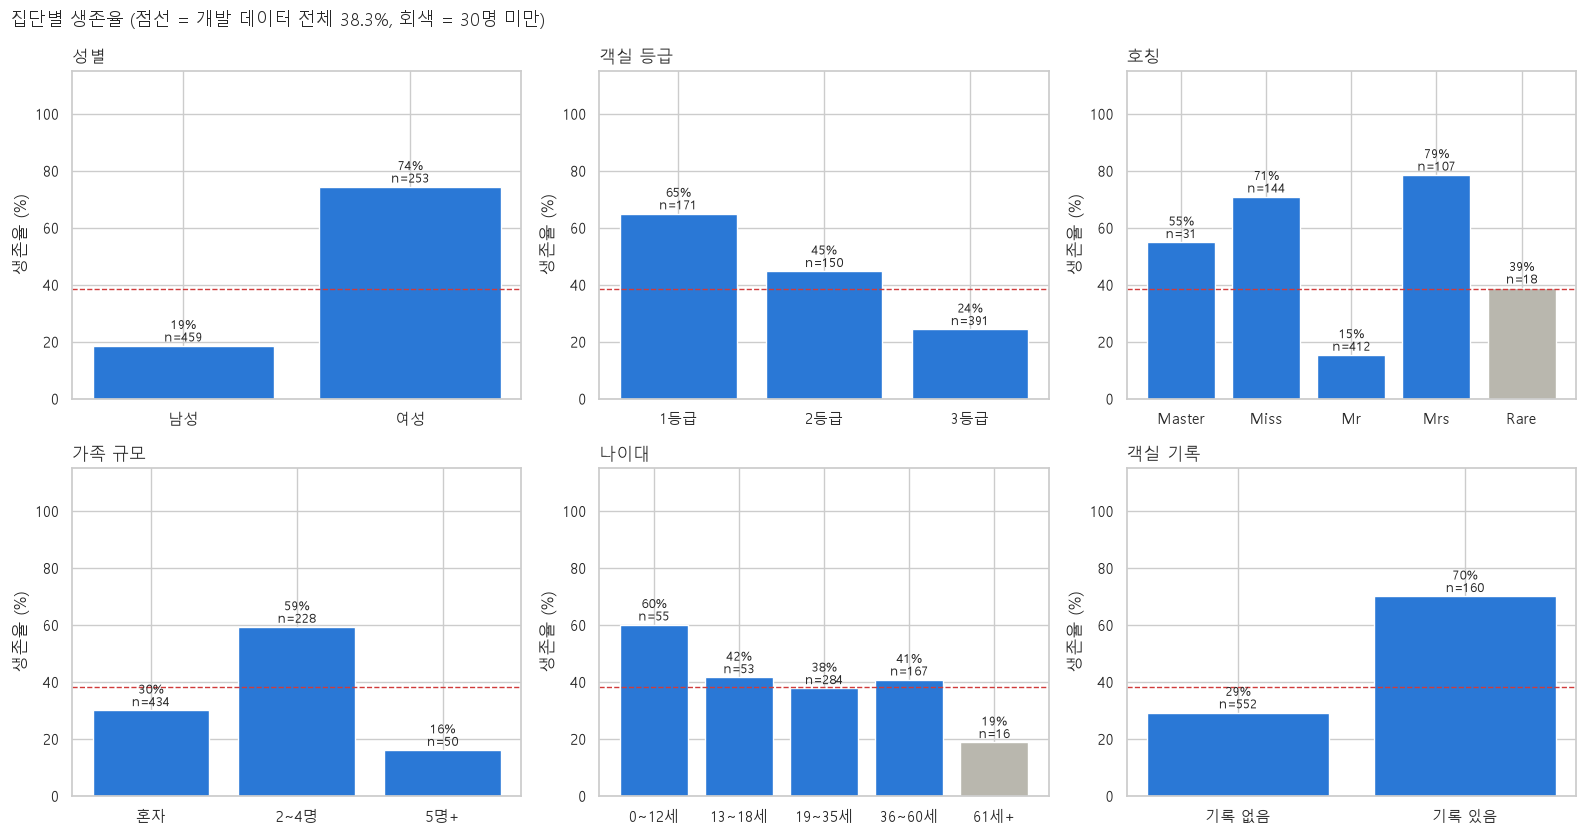

In [5]:
# 기준값과 그래프용 라벨
BASE = dev_fe["Survived"].mean()  # 모든 막대와 비교할 전체 생존율 기준선
eda = dev_fe.assign(
    AgeBand=pd.cut(dev_fe["Age"], [0, 12, 18, 35, 60, 100], labels=["0~12세", "13~18세", "19~35세", "36~60세", "61세+"]).astype(str).replace("nan", "나이 결측"),  # 나이를 구간으로 비교하고 결측도 한 집단으로 보기 위해
    Pclass=dev_fe["Pclass"].map({1: "1등급", 2: "2등급", 3: "3등급"}),  # 그래프에서 읽기 쉬운 이름으로 바꾸기 위해
    Sex=dev_fe["Sex"].map({"male": "남성", "female": "여성"}),  # 그래프에서 읽기 쉬운 이름으로 바꾸기 위해
)
panels = {"성별": "Sex", "객실 등급": "Pclass", "호칭": "Title", "가족 규모": "FamilyGroup", "나이대": "AgeBand", "객실 기록": "HasCabin"}  # 그래프 제목과 컬럼을 짝지어 반복하기 위해

# 집단별 생존율 막대그래프
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))  # 변수 6개를 한 화면에서 비교하기 위해
for ax, (title, col) in zip(axes.ravel(), panels.items()):  # 그래프 칸과 변수를 하나씩 짝짓기 위해
    t = eda.groupby(col)["Survived"].agg(생존율="mean", n="size")  # 생존율과 인원을 함께 보기 위해
    if col == "FamilyGroup":  # 가족 규모를 작은 순으로 보이기 위해
        t = t.loc[["혼자", "2~4명", "5명+"]]
    if col == "HasCabin":  # 0/1 대신 의미가 보이는 라벨을 쓰기 위해
        t.index = t.index.map({0: "기록 없음", 1: "기록 있음"})
    bars = ax.bar(t.index.astype(str), t["생존율"] * 100, color=[GRAY if n < 30 else BLUE for n in t["n"]])  # 30명 미만 집단은 회색으로 구분하기 위해
    for bar, rate, n in zip(bars, t["생존율"], t["n"]):  # 막대마다 값을 적기 위해
        ax.text(bar.get_x() + bar.get_width() / 2, rate * 100 + 1.5, f"{rate:.0%}\nn={n}", ha="center", fontsize=9)  # 생존율과 인원을 함께 보여 신뢰도를 알리기 위해
    ax.axhline(BASE * 100, color=RED, linestyle="--", linewidth=1)  # 전체 생존율과 비교하기 위해
    ax.set_ylim(0, 115)  # 막대 위 글자가 잘리지 않도록
    ax.set_title(title, loc="left", fontsize=12)  # 어떤 변수인지 알리기 위해
    ax.set_ylabel("생존율 (%)")  # 세로축 단위를 알리기 위해
fig.suptitle(f"집단별 생존율 (점선 = 개발 데이터 전체 {BASE:.1%}, 회색 = 30명 미만)", x=0.01, ha="left", fontsize=13)  # 읽는 법을 한 번만 안내하기 위해
plt.tight_layout()  # 라벨이 겹치지 않도록
plt.show()  # 그래프를 출력하기 위해

**결과 해설**

```
전체 생존율 38.3%        : 빨간 점선 기준
성별 여성 74% · 남성 19% : 가장 큰 차이, "여성과 아이 먼저" 원칙과 일치
객실 등급 65% → 24%      : 1등급 → 3등급으로 갈수록 하락
호칭 Master 55% · Mr 15% : 같은 남성이라도 소년(Master)의 생존율이 훨씬 높음
가족 규모 2~4명 59%      : 혼자(30%) · 5명+(16%)보다 높음 → 구간 변수가 유용
나이대 0~12세 60%        : 아이만 뚜렷하게 높음
객실 기록 있음 70%       : 기록 없음(29%)의 2배 이상
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| cut() · assign() · groupby() · agg() | pandas | 나이 구간 · 라벨 교체 · 집단별 집계 | `eda.groupby(col)["Survived"].agg(생존율="mean", n="size")` |
| map() · astype() · replace() | pandas.Series | 라벨 변환 · 문자열 · 값 바꾸기 | `.astype(str).replace("nan", "나이 결측")` |
| subplots() · bar() · text()<br>axhline() · suptitle() | matplotlib | 2 × 3 칸 · 막대 · 글자<br>기준선 · 전체 제목 | `plt.subplots(2, 3, ...)` · `ax.bar(...)`<br>`fig.suptitle(...)` |
| ravel() · zip() | numpy · 내장 함수 | 축 펼치기 · 짝짓기 | `zip(axes.ravel(), panels.items())` |
| 조건 컴프리헨션 | Python 기본 문법 | 인원 따라 색 선택 | `[GRAY if n < 30 else BLUE for n in t["n"]]` |

### 1-3. 성별 × 객실 등급 생존율

**한글 요약**

성별과 등급을 동시에 나눈 6개 집단의 생존율을 히트맵으로 비교. 칸마다 생존율과 인원 함께 표시.

**실행 흐름**

1. **입력**: 1-2의 `eda`
2. **처리**: 성별 × 등급 피벗(생존율 · 인원) → 칸 글자 = 생존율 + 인원
3. **저장**: `pivot`
4. **출력**: 히트맵

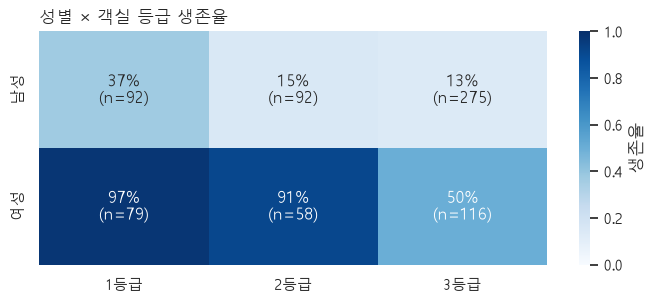

In [6]:
# 성별 × 등급 집계
pivot = eda.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc=["mean", "size"])  # 생존율과 인원을 한 번에 집계하기 위해
annot = pivot["mean"].map("{:.0%}".format) + "\n(n=" + pivot["size"].astype(str) + ")"  # 칸마다 생존율과 인원을 함께 적기 위해

# 히트맵
fig, ax = plt.subplots(figsize=(7, 3.2))  # 그래프 영역을 만들기 위해
sns.heatmap(pivot["mean"], annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar_kws={"label": "생존율"}, ax=ax)  # 진할수록 생존율이 높도록 0~1 고정
ax.set_title("성별 × 객실 등급 생존율", loc="left")  # 그래프 내용을 알리기 위해
ax.set_xlabel("")  # 열 이름이 이미 등급을 알려 주므로 지우기 위해
ax.set_ylabel("")  # 행 이름이 이미 성별을 알려 주므로 지우기 위해
plt.tight_layout()  # 라벨이 겹치지 않도록
plt.show()  # 그래프를 출력하기 위해

**결과 해설**

```
여성 1 · 2등급 97% · 91% : 대부분 생존
여성 3등급 50%           : 같은 여성이라도 절반 수준
남성 1등급 37%           : 남성 중에서는 가장 높음
남성 2 · 3등급 15% · 13% : 대부분 사망
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| pivot_table() · map() · astype() | pandas | 행 × 열 집계 · 백분율 · 문자열 | `eda.pivot_table(index="Sex", columns="Pclass", ...)` |
| heatmap() | seaborn | 색 농도로 값 표시 | `sns.heatmap(pivot["mean"], annot=annot, ...)` |
| subplots() · set_title() · set_xlabel() | matplotlib | 그래프 영역 · 제목 · 축 이름 | `ax.set_title(...)` |
| + (문자열 결합) | Python 기본 문법 | 생존율 · 인원 글자 합치기 | `... + "\n(n=" + ... + ")"` |

### 1-4. 통계 검정: 생존과 관련된 변수

**한글 요약**

- **범주형**: 카이제곱 검정(관련 여부) + **Cramér's V**(관련 강도, 0~1)
- **수치형**: 정규분포를 가정하지 않는 **Mann–Whitney U** 검정 + 효과 크기(rank-biserial), 4개 변수 동시 검정이므로 **Holm 보정**

**실행 흐름**

1. **입력**: `dev_fe`
2. **처리**: 범주형 8개: 교차표 → 카이제곱 p값 · Cramér's V / 수치형 4개: 생존 · 사망 그룹 → U 검정 · 효과 크기 → Holm 보정
3. **저장**: `cat_tests` · `num_tests`
4. **출력**: 검정 결과 표 2개

In [7]:
# 관련 강도 함수
def cramers_v(table):  # 범주 수가 달라도 관련 강도를 비교하기 위해
    chi2 = chi2_contingency(table)[0]  # 정규화에 쓸 카이제곱 통계량을 얻기 위해
    return np.sqrt(chi2 / table.to_numpy().sum() / (min(table.shape) - 1))  # 0(무관) ~ 1(완전 관련)로 맞추기 위해

# 범주형 변수 검정
cat_rows = []  # 변수 1개를 표 1행으로 모으기 위해
for col in ["Sex", "Title", "Pclass", "HasCabin", "FamilyGroup", "Deck", "Embarked", "IsAlone"]:  # 범주형 변수를 같은 방식으로 검정하기 위해
    table = pd.crosstab(dev_fe[col].fillna("결측"), dev_fe["Survived"])  # 결측도 하나의 범주로 넣어 교차표를 만들기 위해
    cat_rows.append({"변수": col, "p값": chi2_contingency(table)[1], "Cramér's V": cramers_v(table)})  # 유의성과 강도를 함께 기록하기 위해
cat_tests = pd.DataFrame(cat_rows).set_index("변수").sort_values("Cramér's V", ascending=False)  # 관련이 강한 순으로 보기 위해

# 수치형 변수 검정
num_rows = []  # 변수 1개를 표 1행으로 모으기 위해
for col in ["Fare", "FarePerPerson", "Age", "FamilySize"]:  # 수치형 변수를 같은 방식으로 검정하기 위해
    died, surv = dev_fe.loc[dev_fe["Survived"].eq(0), col].dropna(), dev_fe.loc[dev_fe["Survived"].eq(1), col].dropna()  # 사망 · 생존 그룹으로 나누기 위해
    u, p = mannwhitneyu(surv, died)  # 정규분포 가정 없이 분포 차이를 검정하기 위해
    num_rows.append({"변수": col, "사망 중앙값": died.median(), "생존 중앙값": surv.median(), "p값": p,
                     "효과 크기 (rank-biserial)": 2 * u / (len(surv) * len(died)) - 1})  # U를 -1~+1로 바꿔 크기를 비교하기 위해 (+면 생존 그룹 값이 큼)
num_tests = pd.DataFrame(num_rows).set_index("변수")  # 변수 이름을 행 이름으로 보기 위해

# Holm 보정
order = np.argsort(num_tests["p값"].to_numpy())  # 작은 p값부터 보정하기 위해
holm = np.maximum.accumulate([(len(order) - r) * num_tests["p값"].iloc[i] for r, i in enumerate(order)])  # 순위별 배수를 곱하되 단조 증가를 유지하기 위해
num_tests.loc[num_tests.index[order], "Holm 보정 p값"] = np.minimum(holm, 1)  # p값이 1을 넘지 않도록

# 결과 표
display(cat_tests.style.format({"p값": "{:.1e}", "Cramér's V": "{:.3f}"}).bar(subset=["Cramér's V"], color="#9ecae1"))  # 강도를 막대로 비교하기 위해
display(num_tests.style.format({"사망 중앙값": "{:.1f}", "생존 중앙값": "{:.1f}", "p값": "{:.1e}", "Holm 보정 p값": "{:.1e}", "효과 크기 (rank-biserial)": "{:+.3f}"}))  # 효과 방향이 보이도록 부호 표시

,p값,Cramér's V
변수,,
Title,2.4e-49,0.573
Sex,4.2e-48,0.546
Deck,2.2e-17,0.368
Pclass,1.9e-19,0.348
HasCabin,2.0e-20,0.347
FamilyGroup,6.1e-15,0.303
IsAlone,1.4e-08,0.213
Embarked,2.0e-06,0.203


,사망 중앙값,생존 중앙값,p값,효과 크기 (rank-biserial),Holm 보정 p값
변수,,,,,
Fare,10.5,26.0,6.9e-20,+0.406,2.8e-19
FarePerPerson,7.9,13.0,2.4e-14,+0.339,7.3e-14
Age,28.2,29.0,2.2e-01,-0.060,2.2e-01
FamilySize,1.0,2.0,1.7e-06,+0.187,3.4e-06


**결과 해설**

```
Title 0.573 · Sex 0.546  : 범주형 중 관련성 압도적
Deck · Pclass · HasCabin : 0.35 안팎으로 뒤를 이음
Fare 효과 크기 +0.406    : 수치형 중 가장 큼 (생존 중앙값 26.0 vs 사망 10.5)
Age Holm 보정 p = 0.22   : 단독으로는 유의하지 않음
```

- 나이는 선형 관계가 아니라 **아이인가 아닌가**로 작용 (1-2: 0~12세 생존율 60%), 이 정보는 호칭 `Master`가 함께 담고 있음

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| cramers_v() | 사용자 정의 함수 | Cramér's V 계산 | `cramers_v(table)` |
| chi2_contingency() · mannwhitneyu() | scipy.stats | 카이제곱 · 순위 기반 비교 | `mannwhitneyu(surv, died)` |
| crosstab() · style.bar() | pandas | 교차표 · 셀 안 막대 | `pd.crosstab(dev_fe[col].fillna("결측"), ...)` |
| argsort() · maximum.accumulate() · minimum() | numpy | 정렬 순서 · 누적 최댓값 · 상한 1 | `np.maximum.accumulate([...])` |
| enumerate() · len() · min() | Python 내장 함수 | 순위 · 개수 · 작은 쪽 | `enumerate(order)` |

---
## 2. 전처리 파이프라인과 기본 모델

### 2-1. 나이 대치기와 전처리 파이프라인

**한글 요약**

- **호칭 × 객실 등급** 중앙값으로 나이를 채우는 전처리기를 직접 정의 (학습 fold 값으로만 계산)
- 모델마다 스케일링 유무를 고를 수 있는 `make_pipe()`, 5겹 교차검증 점수를 한 번에 내는 `cv_eval()` 정의

**실행 흐름**

1. **입력**: `dev_fe` · `holdout_fe`
2. **처리**: 나이 대치기(fit: 중앙값 학습 → transform: 채우기 + AgeMissing) → 변수 목록 → Pipeline 생성 · 교차검증 함수
3. **저장**: `X_dev` · `y_dev` · `X_hold` · `y_hold` · `make_pipe` · `cv_eval` · `cv` · `FMT`
4. **출력**: 입력 데이터 크기

In [8]:
# 호칭 × 등급 나이 대치기
class TitlePclassAgeImputer(BaseEstimator, TransformerMixin):  # Pipeline 안에서 학습 fold 값으로만 대치하기 위해
    """학습 fold에서 구한 '호칭 × 객실 등급' 중앙값으로 Age를 채우고 결측 여부를 남긴다."""
    def fit(self, X, y=None):  # 학습 fold에서만 중앙값을 배우기 위해
        self.group_median_ = X.groupby(["Title", "Pclass"])["Age"].median()  # 1순위: 비슷한 집단의 나이로 채우기 위해 호칭 × 등급 중앙값
        self.title_median_ = X.groupby("Title")["Age"].median()  # 2순위: 집단이 비었을 때를 대비해 호칭 중앙값
        self.global_median_ = X["Age"].median()  # 3순위: 그래도 비면 전체 중앙값
        return self  # Pipeline이 이어서 transform을 부르도록
    def transform(self, X):  # 학습 · 검증 데이터에 같은 규칙으로 채우기 위해
        X = X.copy()  # 입력 원본이 바뀌지 않도록
        miss = X["Age"].isna()  # 채울 위치를 기억하기 위해
        by_group = pd.Series([self.group_median_.get(k, np.nan) for k in zip(X["Title"], X["Pclass"])], index=X.index)  # 행마다 집단 중앙값을 찾기 위해 (없으면 NaN)
        X.loc[miss, "Age"] = by_group[miss].fillna(X.loc[miss, "Title"].map(self.title_median_)).fillna(self.global_median_)  # 1 → 2 → 3순위로 빈칸을 채우기 위해
        X["AgeMissing"] = miss.astype(int)  # 결측 자체도 정보로 남기기 위해
        return X  # 다음 전처리 단계로 넘기기 위해

# 입력 변수
NUM = ["Age", "Fare", "FarePerPerson", "SibSp", "Parch", "FamilySize", "AgeMissing"]  # 수치형 변수 목록을 한곳에 두기 위해
CAT = ["Pclass", "Sex", "Embarked", "Title", "FamilyGroup", "IsAlone", "HasCabin", "Deck"]  # 범주형 변수 목록을 한곳에 두기 위해
X_dev, y_dev = dev_fe[[c for c in NUM if c != "AgeMissing"] + CAT], dev_fe["Survived"]  # AgeMissing은 대치기가 만들기 때문에 입력에서 제외
X_hold, y_hold = holdout_fe[X_dev.columns], holdout_fe["Survived"]  # 최종 평가 데이터도 같은 컬럼 순서로 맞추기 위해

# 전처리 + 모델 Pipeline
def make_pipe(model, scaler=StandardScaler(), num=None, cat=None):  # 모델마다 같은 전처리를 반복해서 만들기 위해
    """거리·선형 모델은 스케일링, 트리 모델은 scaler=None으로 스케일링 생략 (num/cat 기본값 = 현재 NUM/CAT)"""
    num, cat = num or NUM, cat or CAT  # 지정하지 않으면 현재 변수 목록을 쓰기 위해
    num_steps = [("impute", SimpleImputer(strategy="median"))] + ([("scale", clone(scaler))] if scaler is not None else [])  # 트리 모델은 스케일링을 빼기 위해
    prep = ColumnTransformer([
        ("num", Pipeline(num_steps), num),  # 수치형: 대치 (+ 스케일링)
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),  # 범주형 결측을 최빈값으로 채우기 위해
                          ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10))]), cat),  # 10명 미만 범주에 과적합하지 않도록 하나로 묶음
    ])
    return Pipeline([("age", TitlePclassAgeImputer()), ("prep", prep), ("model", model)])  # 나이 대치 → 전처리 → 모델 순서로 묶기 위해

# 교차검증 평가
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)  # 겹마다 생존 비율을 같게 하기 위해
def cv_eval(pipe, X=X_dev):  # 모든 비교를 같은 5겹으로 평가하기 위해
    s = cross_validate(pipe, X, y_dev, cv=cv, scoring=["accuracy", "roc_auc"], return_train_score=True, n_jobs=-1)  # 과적합을 보기 위해 학습 점수도 함께
    return {"CV 정확도": s["test_accuracy"].mean(), "표준편차": s["test_accuracy"].std(), "CV ROC-AUC": s["test_roc_auc"].mean(),
            "학습-CV 차이": s["train_accuracy"].mean() - s["test_accuracy"].mean()}  # 차이가 클수록 과적합임을 보이기 위해
FMT = {"CV 정확도": "{:.3f}", "표준편차": "{:.3f}", "CV ROC-AUC": "{:.3f}", "학습-CV 차이": "{:+.3f}"}  # 결과 표 서식을 통일하기 위해

# 데이터 크기 확인
print("개발 데이터:", X_dev.shape, "| 최종 평가 데이터:", X_hold.shape)  # 두 입력의 컬럼 수가 같은지 확인하기 위해

개발 데이터: (712, 14) | 최종 평가 데이터: (179, 14)


**결과 해설**

```
(712, 14) · (179, 14) : 수치형 6개 + 범주형 8개, AgeMissing은 Pipeline 안에서 추가
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| TitlePclassAgeImputer | 사용자 정의 클래스 | 호칭 × 등급 나이 대치 | `("age", TitlePclassAgeImputer())` |
| make_pipe() · cv_eval() | 사용자 정의 함수 | Pipeline 생성 · CV 점수 요약 | `cv_eval(make_pipe(model, scaler))` |
| BaseEstimator · TransformerMixin · clone() | sklearn.base | 전처리기 틀 · 설정 복제 | `clone(scaler)` |
| SimpleImputer() · ColumnTransformer()<br>OneHotEncoder() · Pipeline() | sklearn | 대치 · 컬럼별 전처리<br>원-핫 · 단계 연결 | `OneHotEncoder(..., min_frequency=10)` |
| StratifiedKFold() · cross_validate() | sklearn.model_selection | 비율 유지 5겹 · 점수 | `cross_validate(pipe, X, y_dev, cv=cv, ...)` |
| Series() · groupby() · median() · get() | pandas | 행별 중앙값 · 집단 중앙값 · 안전 조회 | `self.group_median_.get(k, np.nan)` |
| class · self · or | Python 기본 문법 | 클래스 · 객체 자신 · 기본값 대체 | `num or NUM` |

### 2-2. 가족 정보 표현 비교

**한글 요약**

- `SibSp` · `Parch` 원본, 합친 `FamilySize`, 구간 `FamilyGroup`, `IsAlone`은 모두 같은 정보의 다른 표현
- 하나만 남겼을 때 로지스틱 회귀 · 랜덤 포레스트의 CV 정확도 비교 → 성능이 같으면 **단순한 쪽** 선택

**실행 흐름**

1. **입력**: `X_dev` · `y_dev`
2. **처리**: 가족 외 공통 변수 → 가족 변수 표현 5가지 → 표현 5 × 모델 2 교차검증
3. **저장**: `family_table`, 최종 입력 변수 `NUM` · `CAT`
4. **출력**: 표현 × 모델 표, 최종 입력 변수

In [9]:
# 가족 외 공통 변수
base_num = ["Age", "Fare", "FarePerPerson", "AgeMissing"]  # 가족 변수만 바꿔 비교하기 위해 나머지 수치형 고정
base_cat = ["Pclass", "Sex", "Embarked", "Title", "HasCabin", "Deck"]  # 가족 변수만 바꿔 비교하기 위해 나머지 범주형 고정

# 가족 변수 표현 5가지: 이름 → (수치형, 범주형)
family_sets = {
    "SibSp + Parch": (["SibSp", "Parch"], []),  # 원본 그대로를 기준으로 보기 위해
    "FamilySize": (["FamilySize"], []),  # 하나로 합친 표현
    "FamilyGroup (구간)": ([], ["FamilyGroup"]),  # 단조가 아닌 관계를 구간으로
    "IsAlone": ([], ["IsAlone"]),  # 혼자 여부만 남긴 표현
    "전부 사용": (["SibSp", "Parch", "FamilySize"], ["FamilyGroup", "IsAlone"]),  # 중복 정보를 모두 넣었을 때와 비교하기 위해
}

# 표현 × 모델 교차검증
rows = []  # 결과를 한 표로 모으기 위해
for set_name, (fnum, fcat) in family_sets.items():  # 표현을 하나씩 바꿔 보기 위해
    for model_name, model, scaler in [("로지스틱 회귀", LogisticRegression(max_iter=2000), StandardScaler()),
                                      ("랜덤 포레스트", RandomForestClassifier(300, max_depth=6, random_state=RANDOM_STATE), None)]:  # 선형 · 트리 모델 모두에서 확인하기 위해 (트리는 스케일링 생략)
        pipe = make_pipe(model, scaler, num=base_num + fnum, cat=base_cat + fcat)  # 가족 변수만 바꾼 Pipeline을 만들기 위해
        rows.append({"가족 변수": set_name, "모델": model_name, "CV 정확도": cv_eval(pipe)["CV 정확도"]})  # 같은 5겹 점수로 비교하기 위해
family_table = pd.DataFrame(rows).pivot(index="가족 변수", columns="모델", values="CV 정확도")  # 표현 × 모델 표로 보기 위해
display(family_table.style.format("{:.3f}").highlight_max(axis=0, color="#d4edda"))  # 모델별 최고값을 강조하기 위해

# 최종 입력 변수: 같은 성능이면 단순한 쪽
NUM = base_num + ["FamilySize"]  # 성능이 같다면 변수 하나로 단순하게 표현하기 위해
CAT = base_cat  # 가족 범주형 변수는 빼기 위해
print("최종 입력 변수 —", "수치형:", NUM, "| 범주형:", CAT)  # 이후 단계에서 쓸 변수를 확인하기 위해

모델,랜덤 포레스트,로지스틱 회귀
가족 변수,,
FamilyGroup (구간),0.827,0.830
FamilySize,0.830,0.830
IsAlone,0.823,0.816
SibSp + Parch,0.820,0.829
전부 사용,0.823,0.829


최종 입력 변수 — 수치형: ['Age', 'Fare', 'FarePerPerson', 'AgeMissing', 'FamilySize'] | 범주형: ['Pclass', 'Sex', 'Embarked', 'Title', 'HasCabin', 'Deck']


**결과 해설**

```
FamilySize 0.830 · 0.830 : 두 모델 모두 가장 높거나 같음
표현별 차이 0.014 이내   : 가족 정보를 어떻게 넣어도 성능 차이 작음
최종 입력 변수           : 수치형 5개 + 범주형 6개, 가족은 FamilySize 하나
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| LogisticRegression() · RandomForestClassifier() | sklearn | 선형 모델 · 트리 300개 | `RandomForestClassifier(300, max_depth=6, ...)` |
| pivot() · style.highlight_max() | pandas.DataFrame | 표현 × 모델 표 · 최고값 강조 | `.pivot(index="가족 변수", columns="모델", ...)` |
| make_pipe() · cv_eval() | 사용자 정의 함수 | Pipeline · CV 정확도 | `cv_eval(pipe)["CV 정확도"]` |
| append() · print() | list · 내장 함수 | 결과 행 추가 · 출력 | `rows.append({...})` |
| 튜플 언패킹 · + (리스트 결합) | Python 기본 문법 | (수치형, 범주형) 분리 · 목록 합치기 | `base_num + fnum` |

### 2-3. 모델에 맞는 전처리: 스케일러 비교

**한글 요약**

- **KNN**은 거리, **로지스틱 회귀**는 가중합으로 계산 → 운임(0~500)처럼 단위가 큰 변수가 결과를 지배하지 않도록 **스케일링 필요**
- **트리**는 한 변수의 순서로만 나누므로 스케일링 의미 없음
- StandardScaler · MinMaxScaler · RobustScaler · 스케일링 없음 비교

**실행 흐름**

1. **입력**: `X_dev` · `y_dev`
2. **처리**: 모델 2 × 스케일러 4 조합 → 조합별 5겹 교차검증
3. **저장**: `scaler_table`
4. **출력**: 조합별 점수 표 (CV 정확도 최고값 강조)

In [10]:
# 모델 × 스케일러 교차검증
rows = []  # 결과를 한 표로 모으기 위해
for model_name, model in {"로지스틱 회귀": LogisticRegression(max_iter=2000), "KNN (k=11)": KNeighborsClassifier(11)}.items():  # 스케일링에 민감한 두 모델을 비교하기 위해
    for scaler_name, scaler in {"StandardScaler": StandardScaler(), "MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler(), "스케일링 없음": None}.items():  # 스케일러 효과를 보기 위해
        rows.append({"모델": model_name, "스케일러": scaler_name, **cv_eval(make_pipe(model, scaler))})  # 점수 4개를 한 행에 펼치기 위해

# 결과 표
scaler_table = pd.DataFrame(rows).set_index(["모델", "스케일러"])  # 모델 · 스케일러를 2단 행 이름으로 보기 위해
scaler_table.style.format(FMT).highlight_max(subset=["CV 정확도"], color="#d4edda")  # 가장 좋은 조합을 강조하기 위해

**결과 해설**

```
KNN 스케일링 없음 0.737   : 스케일링 시 0.801~0.805 → 단위 큰 운임이 거리 지배
로지스틱 회귀 0.829~0.830 : 스케일러와 상관없이 거의 같음
기본값                    : 계수 비교 · 학습 안정성을 위해 StandardScaler 사용
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| KNeighborsClassifier() · MinMaxScaler() · RobustScaler() | sklearn | 11명 다수결 · 0~1 변환 · 중앙값 · IQR 기준 | `KNeighborsClassifier(11)` |
| set_index() · style.format() | pandas.DataFrame | 2단 행 이름 · 서식 | `.set_index(["모델", "스케일러"])` |
| make_pipe() · cv_eval() | 사용자 정의 함수 | 조합별 Pipeline · 점수 | `cv_eval(make_pipe(model, scaler))` |
| ** (딕셔너리 펼치기) | Python 기본 문법 | 점수를 한 행에 합치기 | `{"모델": ..., **cv_eval(...)}` |

### 2-4. 기본 모델 비교 (튜닝 전)

**한글 요약**

로지스틱 회귀 · KNN · 결정 트리(깊이 제한 없음 / 깊이 4)의 기본 설정 성능과 **학습-CV 차이**(과적합 정도) 비교.

**실행 흐름**

1. **입력**: `X_dev` · `y_dev`
2. **처리**: 기본 모델 4개 Pipeline → 모델별 5겹 교차검증
3. **저장**: `baseline_table`
4. **출력**: 모델별 점수 표

In [11]:
# 기본 모델 4개
baseline = {
    "로지스틱 회귀": make_pipe(LogisticRegression(max_iter=2000)),  # 선형 모델의 기준 성능을 보기 위해
    "KNN (k=11)": make_pipe(KNeighborsClassifier(11)),  # 거리 기반 모델과 비교하기 위해
    "결정 트리 (깊이 제한 없음)": make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE), None),  # 제한 없는 트리의 과적합을 보기 위해 (스케일링 생략)
    "결정 트리 (깊이 4)": make_pipe(DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE), None),  # 깊이 제한의 효과를 보기 위해
}

# 결과 표
baseline_table = pd.DataFrame({name: cv_eval(pipe) for name, pipe in baseline.items()}).T  # 모델을 행으로 비교하기 위해
baseline_table.style.format(FMT)  # 공통 서식으로 출력하기 위해

,CV 정확도,표준편차,CV ROC-AUC,학습-CV 차이
로지스틱 회귀,0.830,0.020,0.872,+0.012
KNN (k=11),0.801,0.016,0.862,+0.033
결정 트리 (깊이 제한 없음),0.787,0.032,0.773,+0.202
결정 트리 (깊이 4),0.826,0.037,0.873,+0.040


**결과 해설**

```
로지스틱 회귀 0.830         : 기본 설정 중 최고
결정 트리 (제한 없음) 0.787 : 학습-CV 차이 +0.202 → 학습 데이터를 거의 외움
결정 트리 (깊이 4) 0.826    : 깊이 제한만으로 차이 +0.040까지 감소
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| DecisionTreeClassifier() | sklearn.tree | 결정 트리 (깊이 제한 유무) | `DecisionTreeClassifier(max_depth=4, ...)` |
| DataFrame() · T · style.format() | pandas | 결과 표 · 행열 전환 · 서식 | `pd.DataFrame({...}).T` |
| { ... for ... } | Python 기본 문법 | 모델 이름 → 점수 | `{name: cv_eval(pipe) for name, pipe in baseline.items()}` |

### 2-5. 결정 트리의 높은 분산

**한글 요약**

- 트리는 데이터가 조금만 바뀌어도 판단이 크게 흔들림
- **겹치는 부분이 많은 두 학습 표본**으로 같은 트리를 만들고, 처음 보는 100명에 대한 예측 비교

**실행 흐름**

1. **입력**: `X_dev` · `y_dev`
2. **처리**: 앞 612명 = 학습 후보 · 뒤 100명 = 확인용 → 후보에서 550명씩 두 번 추출 → 트리 2개 학습 → 예측 비교
3. **저장**: `pred_a` · `pred_b`
4. **출력**: 두 표본 공통 승객 수, 예측이 다른 승객 수

In [12]:
# 두 학습 표본
rng = np.random.default_rng(RANDOM_STATE)  # 다시 실행해도 같은 표본이 뽑히도록
pool, probe = np.arange(612), np.arange(612, len(X_dev))  # 학습 후보 612명과 처음 보는 확인용 100명을 나누기 위해
sample_a, sample_b = rng.choice(pool, 550, replace=False), rng.choice(pool, 550, replace=False)  # 많이 겹치는 두 표본을 만들기 위해 550명씩

# 같은 설정의 트리 2개 학습 · 예측
deep_tree = make_pipe(DecisionTreeClassifier(min_samples_leaf=2, random_state=RANDOM_STATE), None)  # 분산이 큰 깊은 트리를 보기 위해
pred_a = clone(deep_tree).fit(X_dev.iloc[sample_a], y_dev.iloc[sample_a]).predict(X_dev.iloc[probe])  # 표본 A로 학습한 트리의 판단을 보기 위해
pred_b = clone(deep_tree).fit(X_dev.iloc[sample_b], y_dev.iloc[sample_b]).predict(X_dev.iloc[probe])  # 표본 B로 학습한 트리의 판단을 보기 위해

# 결과 비교
print(f"두 학습 표본의 공통 승객: {len(set(sample_a) & set(sample_b))} / 550명")  # 표본이 얼마나 겹치는지 보이기 위해
print(f"처음 보는 {len(probe)}명 중 두 트리의 예측이 다른 승객: {(pred_a != pred_b).sum()}명")  # 판단이 얼마나 흔들리는지 보이기 위해

두 학습 표본의 공통 승객: 495 / 550명
처음 보는 100명 중 두 트리의 예측이 다른 승객: 13명


**결과 해설**

```
공통 승객 495 / 550명 : 학습 데이터의 90%가 같음
예측이 다른 승객 13명 : 그런데도 100명 중 13명의 판단이 바뀜 → 트리의 높은 분산
```

- 서로 다른 표본으로 만든 트리 여러 개의 판단을 모으는 **배깅 · 랜덤 포레스트**, 앞 모델의 오차를 순서대로 고치는 **부스팅**이 필요한 이유

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| default_rng() · choice() · arange() | numpy | 재현 가능한 추출 · 연속 번호 | `rng.choice(pool, 550, replace=False)` |
| clone() · fit() · predict() | sklearn | 새 모델 · 학습 · 예측 | `clone(deep_tree).fit(...).predict(...)` |
| iloc[] | pandas | 위치로 행 선택 | `X_dev.iloc[sample_a]` |
| & (집합 교집합) · != · sum() | Python · numpy | 공통 승객 · 예측 불일치 수 | `set(sample_a) & set(sample_b)` |

---
## 3. 하이퍼파라미터 튜닝과 앙상블

### 3-1. GridSearchCV와 중첩 교차검증

**한글 요약**

- 6개 모델의 설정 후보를 GridSearchCV로 탐색
- GridSearchCV가 고른 설정의 CV 점수는 **설정을 고르는 데 이미 쓴 점수** → 낙관적
- **중첩 교차검증**으로 튜닝 과정까지 포함한 성능을 따로 추정: 바깥 5겹 = 성능 측정, 안쪽 5겹 = 설정 선택

**실행 흐름**

1. **입력**: `X_dev` · `y_dev`
2. **처리**: 모델 6개 × 설정 후보 → 안쪽 5겹 GridSearchCV → 바깥 5겹 중첩 CV → 개발 데이터 전체로 최종 설정
3. **저장**: `tuned` (모델별 최종 Pipeline) · `tuned_table`
4. **출력**: 선택 과정 CV vs 중첩 CV 비교 표

In [13]:
# 모델별 설정 후보: 이름 → (Pipeline, 탐색 범위)
search_spaces = {
    "로지스틱 회귀": (make_pipe(LogisticRegression(max_iter=3000)),
                {"model__C": [0.03, 0.1, 0.3, 1, 3, 10]}),  # 규제 강도를 고르기 위해
    "KNN": (make_pipe(KNeighborsClassifier()),
            {"model__n_neighbors": [5, 9, 13, 17, 21], "model__weights": ["uniform", "distance"]}),  # 이웃 수 · 가중 방식을 고르기 위해
    "결정 트리": (make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE), None),
              {"model__max_depth": [3, 4, 5, 6, 8], "model__min_samples_leaf": [1, 5, 10]}),  # 깊이 · 잎 최소 인원으로 과적합을 조절하기 위해
    "랜덤 포레스트": (make_pipe(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE), None),
                {"model__max_depth": [5, 7, None], "model__min_samples_leaf": [1, 3, 5], "model__max_features": ["sqrt", 0.5]}),  # 트리 깊이 · 다양성을 고르기 위해
    "그래디언트 부스팅": (make_pipe(GradientBoostingClassifier(random_state=RANDOM_STATE), None),
                  {"model__n_estimators": [100, 200], "model__learning_rate": [0.05, 0.1], "model__max_depth": [2, 3]}),  # 반복 횟수와 학습률을 함께 고르기 위해
    "XGBoost": (make_pipe(XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1), None),
                {"model__n_estimators": [200, 400], "model__learning_rate": [0.03, 0.1], "model__max_depth": [2, 3, 4], "model__subsample": [0.8, 1.0]}),  # 규제 포함 부스팅 설정을 고르기 위해
}
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1)  # 바깥 5겹과 다른 분할로 설정을 고르기 위해

# 튜닝 + 중첩 교차검증
tuned, rows = {}, []  # 모델별 최종 설정과 결과 행을 모으기 위해
for name, (pipe, grid) in search_spaces.items():  # 모델을 하나씩 튜닝하기 위해
    search = GridSearchCV(pipe, grid, cv=inner_cv, scoring="accuracy", n_jobs=-1)  # 안쪽 5겹으로 설정을 고르기 위해
    nested = cross_validate(search, X_dev, y_dev, cv=cv, scoring="accuracy", return_train_score=True)  # 튜닝 과정까지 포함한 성능을 바깥 5겹으로 재기 위해
    search.fit(X_dev, y_dev)  # 개발 데이터 전체로 최종 설정을 고르기 위해
    tuned[name] = search.best_estimator_  # 3-3 앙상블 · 4장에서 쓰기 위해
    rows.append({"모델": name,
                 "선택된 설정": ", ".join(f"{k.split('__')[1]}={v}" for k, v in search.best_params_.items()),  # model__C → C로 짧게 보이기 위해
                 "선택 과정 CV (낙관적)": search.best_score_,  # 낙관 편향을 비교하기 위해
                 "중첩 CV": nested["test_score"].mean(), "표준편차": nested["test_score"].std(),  # 튜닝을 포함한 성능과 흔들림을 보기 위해
                 "학습-CV 차이": nested["train_score"].mean() - nested["test_score"].mean()})  # 과적합 정도를 보기 위해

# 결과 표
tuned_table = pd.DataFrame(rows).set_index("모델").sort_values("중첩 CV", ascending=False)  # 중첩 CV가 높은 순으로 보기 위해
tuned_table.style.format({"선택 과정 CV (낙관적)": "{:.3f}", "중첩 CV": "{:.3f}", "표준편차": "{:.3f}", "학습-CV 차이": "{:+.3f}"})  # 소수 셋째 자리로 비교하기 위해

,선택된 설정,선택 과정 CV (낙관적),중첩 CV,표준편차,학습-CV 차이
모델,,,,,
로지스틱 회귀,C=1,0.826,0.827,0.021,+0.016
결정 트리,"max_depth=5, min_samples_leaf=5",0.827,0.825,0.029,+0.048
랜덤 포레스트,"max_depth=7, max_features=0.5, min_samples_leaf=5",0.843,0.824,0.029,+0.066
XGBoost,"learning_rate=0.03, max_depth=3, n_estimators=200, subsample=0.8",0.840,0.822,0.028,+0.083
그래디언트 부스팅,"learning_rate=0.1, max_depth=3, n_estimators=200",0.831,0.819,0.030,+0.091
KNN,"n_neighbors=17, weights=uniform",0.823,0.806,0.007,+0.032


**결과 해설**

```
로지스틱 회귀 0.827 (C=1)   : 중첩 CV 1위, 학습-CV 차이 +0.016으로 가장 작음
랜덤 포레스트 0.843 → 0.824 : 선택 과정 CV가 가장 높았지만 중첩 CV에서 하락
XGBoost 0.840 → 0.822       : 같은 낙관 편향
부스팅 계열 학습-CV 차이    : +0.083 · +0.091로 과적합 경향 가장 큼
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| GridSearchCV()<br>best_estimator_ · best_params_ · best_score_ | sklearn.model_selection | 설정 전수 탐색<br>최종 모델 · 설정 · 점수 | `GridSearchCV(pipe, grid, cv=inner_cv, ...)`<br>`search.best_params_.items()` |
| cross_validate() · StratifiedKFold() | sklearn.model_selection | 바깥 5겹 · 안쪽 분할 | `cross_validate(search, X_dev, y_dev, cv=cv, ...)` |
| GradientBoostingClassifier() · XGBClassifier() | sklearn · xgboost | 순차 부스팅 · 규제 포함 부스팅 | `XGBClassifier(eval_metric="logloss", ...)` |
| join() · split() | Python str | 설정 문자열 합치기 · 접두어 제거 | `k.split('__')[1]` |
| 제너레이터 표현식 · 튜플 언패킹 | Python 기본 문법 | "이름=값" 나열 · (Pipeline, 범위) 분리 | `for name, (pipe, grid) in search_spaces.items():` |

### 3-2. 부스팅은 언제 멈춰야 하는가

**한글 요약**

- 부스팅은 반복할수록 학습 손실이 계속 줄지만, **검증 손실은 어느 순간부터 다시 증가**(과적합)
- 개발 데이터를 한 번 더 75 : 25로 나눠 반복 횟수별 손실 확인

**실행 흐름**

1. **입력**: `X_dev` · `y_dev`
2. **처리**: 75 : 25 분할 → 부스팅 400회 학습 → 반복마다 학습 · 검증 로그 손실 → 검증 손실 최소 지점
3. **저장**: `train_loss` · `valid_loss` · `best_round`
4. **출력**: 손실 곡선, 400회 vs 최소 지점 손실

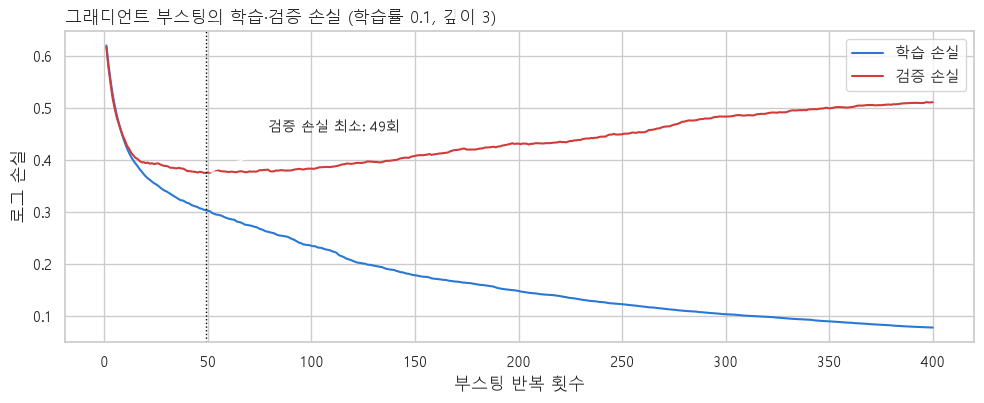

400회 반복 시 검증 손실 0.511 vs 최소 0.375 (49회)


In [14]:
# 학습 · 검증 분할
X_t, X_v, y_t, y_v = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=RANDOM_STATE)  # 최종 평가 데이터를 건드리지 않고 개발 데이터 안에서만 분할

# 400회 부스팅 학습
gb_demo = make_pipe(GradientBoostingClassifier(n_estimators=400, learning_rate=0.1, max_depth=3, random_state=RANDOM_STATE), None).fit(X_t, y_t)  # 과적합 지점을 보기 위해 충분히 길게 학습
prep_t = gb_demo[:-1].transform(X_t)  # 모델에 들어가는 형태로 학습 데이터를 바꾸기 위해
prep_v = gb_demo[:-1].transform(X_v)  # 같은 전처리를 검증 데이터에도 적용하기 위해

# 반복 횟수별 손실
train_loss = [log_loss(y_t, p) for p in gb_demo[-1].staged_predict_proba(prep_t)]  # 1~400회 각 시점의 학습 손실을 보기 위해
valid_loss = [log_loss(y_v, p) for p in gb_demo[-1].staged_predict_proba(prep_v)]  # 각 시점의 검증 손실을 보기 위해
best_round = int(np.argmin(valid_loss)) + 1  # 검증 손실이 가장 낮은 반복 횟수를 찾기 위해 (1부터 셈)

# 손실 곡선
fig, ax = plt.subplots(figsize=(10, 4.2))  # 그래프 영역을 만들기 위해
ax.plot(range(1, 401), train_loss, color=BLUE, label="학습 손실")  # 학습 손실이 계속 주는지 보기 위해
ax.plot(range(1, 401), valid_loss, color=RED, label="검증 손실")  # 검증 손실이 다시 오르는지 보기 위해
ax.axvline(best_round, color="black", linestyle=":", linewidth=1)  # 최소 지점을 표시하기 위해
ax.annotate(f"검증 손실 최소: {best_round}회", (best_round, min(valid_loss)), xytext=(best_round + 30, min(valid_loss) + 0.08),
            arrowprops=dict(arrowstyle="->"), fontsize=10)  # 최소 지점을 화살표로 설명하기 위해
ax.set_xlabel("부스팅 반복 횟수")  # 가로축 의미를 알리기 위해
ax.set_ylabel("로그 손실")  # 세로축 의미를 알리기 위해
ax.set_title("그래디언트 부스팅의 학습·검증 손실 (학습률 0.1, 깊이 3)", loc="left")  # 어떤 설정인지 알리기 위해
ax.legend()  # 두 선을 구분하기 위해
plt.tight_layout()  # 라벨이 겹치지 않도록
plt.show()  # 그래프를 출력하기 위해
print(f"400회 반복 시 검증 손실 {valid_loss[-1]:.3f} vs 최소 {min(valid_loss):.3f} ({best_round}회)")  # 너무 오래 학습한 손해를 숫자로 보이기 위해

**결과 해설**

```
검증 손실 최소 49회 · 0.375 : 이후 계속 반복하면 검증 손실 증가
400회 반복 시 0.511         : 학습 손실은 계속 줄지만 학습 데이터에만 맞춰짐
```

- 튜닝에서 **반복 횟수와 학습률을 함께** 탐색하고, 실무에서 **조기 종료**를 쓰는 이유

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| GradientBoostingClassifier() · staged_predict_proba()<br>[:-1] · [-1] · transform() | sklearn | 400회 부스팅 · 시점별 확률<br>Pipeline 전처리 · 모델 부분 | `gb_demo[-1].staged_predict_proba(prep_t)`<br>`gb_demo[:-1].transform(X_t)` |
| log_loss() | sklearn.metrics | 확률 예측 손실 | `log_loss(y_t, p)` |
| argmin() | numpy | 최솟값 위치 | `np.argmin(valid_loss)` |
| plot() · axvline() · annotate() | matplotlib | 선 · 세로선 · 화살표 설명 | `ax.annotate(f"검증 손실 최소: ...", ...)` |
| range() · min() · dict() | Python 내장 함수 | 반복 축 · 최솟값 · 화살표 설정 | `range(1, 401)` |

### 3-3. 앙상블: Soft Voting과 Stacking

**한글 요약**

- 튜닝된 로지스틱 회귀 · 랜덤 포레스트 · 그래디언트 부스팅 · XGBoost 4개 결합
- **Soft Voting**: 4개 모델의 생존 확률 평균 / **Stacking**: 4개 모델의 예측을 입력으로 로지스틱 회귀가 최종 판단

**실행 흐름**

1. **입력**: 3-1의 `tuned`
2. **처리**: 구성 모델 4개 → Soft Voting · Stacking 구성 → 5겹 교차검증
3. **저장**: `ensembles` · `ens_table`
4. **출력**: 앙상블 점수 표

In [15]:
# 앙상블 구성
members = [("lr", tuned["로지스틱 회귀"]), ("rf", tuned["랜덤 포레스트"]), ("gb", tuned["그래디언트 부스팅"]), ("xgb", tuned["XGBoost"])]  # 성격이 다른 모델을 섞어 오류를 서로 보완하기 위해
ensembles = {
    "Soft Voting": VotingClassifier(members, voting="soft"),  # 확률을 평균 내 판단하기 위해
    "Stacking": StackingClassifier(members, final_estimator=LogisticRegression(max_iter=2000), cv=5),  # 모델별 예측을 다시 학습해 가중치를 정하기 위해
}

# 앙상블 교차검증
ens_rows = []  # 결과를 한 표로 모으기 위해
for name, model in ensembles.items():  # 두 앙상블을 같은 5겹으로 평가하기 위해
    s = cross_validate(model, X_dev, y_dev, cv=cv, scoring="accuracy", return_train_score=True, n_jobs=-1)  # 과적합을 보기 위해 학습 점수도 함께
    ens_rows.append({"모델": name, "중첩 CV": s["test_score"].mean(), "표준편차": s["test_score"].std(),
                     "학습-CV 차이": s["train_score"].mean() - s["test_score"].mean()})  # 단일 모델 표와 같은 컬럼으로 맞추기 위해

# 결과 표
ens_table = pd.DataFrame(ens_rows).set_index("모델")  # 모델 이름을 행 이름으로 보기 위해
ens_table.style.format({"중첩 CV": "{:.3f}", "표준편차": "{:.3f}", "학습-CV 차이": "{:+.3f}"})  # 3-1 표와 같은 서식으로 비교하기 위해

,중첩 CV,표준편차,학습-CV 차이
모델,,,
Soft Voting,0.826,0.017,+0.085
Stacking,0.831,0.016,+0.067


**결과 해설**

```
Stacking 0.831    : 전체 최고 점수
Soft Voting 0.826 : 로지스틱 회귀 단독(0.827)과 비슷
```

- 구성 모델 설정은 개발 데이터 전체로 고른 값 → 위 점수는 단일 모델의 중첩 CV보다 약간 낙관적일 수 있음

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| VotingClassifier() · StackingClassifier() | sklearn.ensemble | 확률 평균 결합 · 예측 재학습 | `StackingClassifier(members, final_estimator=..., cv=5)` |
| cross_validate() | sklearn.model_selection | 5겹 점수 | `cross_validate(model, X_dev, y_dev, cv=cv, ...)` |
| DataFrame() · set_index() · style.format() | pandas | 결과 표 · 서식 | `pd.DataFrame(ens_rows).set_index("모델")` |
| list · tuple · for | Python 기본 문법 | (이름, 모델) 목록 · 반복 | `members = [("lr", ...), ...]` |

### 3-4. 앙상블은 다른 승객을 맞히는가

**한글 요약**

- 평균 점수가 비슷해도 **맞히는 승객은 다를 수 있음**
- 교차검증 예측(OOF)으로 최고 단일 모델과 Soft Voting이 각각 새로 맞히고 놓치는 승객 수 비교

**실행 흐름**

1. **입력**: `tuned_table` · `tuned` · `ensembles`
2. **처리**: 중첩 CV 1위 단일 모델 → 단일 · Soft Voting OOF 예측 → Voting만 맞힘 · 틀림 집계
3. **저장**: `oof_single` · `oof_vote`
4. **출력**: OOF 정답 수, 순변화

In [16]:
# 교차검증 예측 (모든 승객이 한 번씩 검증 fold)
best_single = tuned_table.index[0]  # 중첩 CV 1위 단일 모델과 비교하기 위해
oof_single = cross_val_predict(tuned[best_single], X_dev, y_dev, cv=cv, n_jobs=-1)  # 모든 승객을 학습에 쓰지 않은 상태로 예측하기 위해
oof_vote = cross_val_predict(ensembles["Soft Voting"], X_dev, y_dev, cv=cv, n_jobs=-1)  # 같은 방식으로 앙상블을 예측하기 위해

# 맞힘 · 틀림 비교
fixed = ((oof_vote == y_dev) & (oof_single != y_dev)).sum()  # 앙상블이 새로 맞힌 승객을 세기 위해
broken = ((oof_vote != y_dev) & (oof_single == y_dev)).sum()  # 앙상블이 새로 틀린 승객을 세기 위해
print(f"기준: {best_single} (OOF 정답 {(oof_single == y_dev).sum()}명) vs Soft Voting (OOF 정답 {(oof_vote == y_dev).sum()}명)")  # 전체 정답 수를 비교하기 위해
print(f"Voting만 맞힘 {fixed}명 · Voting만 틀림 {broken}명 → 순변화 {fixed - broken:+d}명")  # 앙상블이 실제로 나아졌는지 보기 위해

기준: 로지스틱 회귀 (OOF 정답 591명) vs Soft Voting (OOF 정답 588명)
Voting만 맞힘 19명 · Voting만 틀림 22명 → 순변화 -3명


**결과 해설**

```
OOF 정답 591명 vs 588명 : 로지스틱 회귀가 3명 더 맞힘
Voting만 맞힘 19명      : 앙상블이 새로 맞힌 승객
Voting만 틀림 22명      : 앙상블이 새로 틀린 승객 → 순변화 -3명, 자동 개선 아님
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| cross_val_predict() | sklearn.model_selection | 승객별 검증 fold 예측 | `cross_val_predict(tuned[best_single], X_dev, y_dev, cv=cv)` |
| index | pandas.DataFrame | 1위 모델 이름 | `tuned_table.index[0]` |
| == · != · & · sum() | numpy / pandas 비교 | 맞힘 · 틀림 조건 · 개수 | `((oof_vote == y_dev) & (oof_single != y_dev)).sum()` |
| f-string 서식 | Python 기본 문법 | 부호 붙은 정수 | `f"{fixed - broken:+d}"` |

---
## 4. 최종 모델 선택과 평가

### 4-1. 1-SE 규칙으로 최종 모델 선택

**한글 요약**

- 점수 차이가 표준오차 안이라면 우연일 수 있음
- **1-SE 규칙**: 최고 점수에서 표준오차 1개 이내 후보 중 **가장 단순한 모델** 선택

**실행 흐름**

1. **입력**: `tuned_table` · `ens_table`
2. **처리**: 단일 6개 + 앙상블 2개 합치기 → 단순한 순서 부여 → 최고 점수 - 표준오차 기준선 → 가장 단순한 후보
3. **저장**: `summary` · `final_name` · `all_models`
4. **출력**: 1-SE 막대그래프, 결과 표

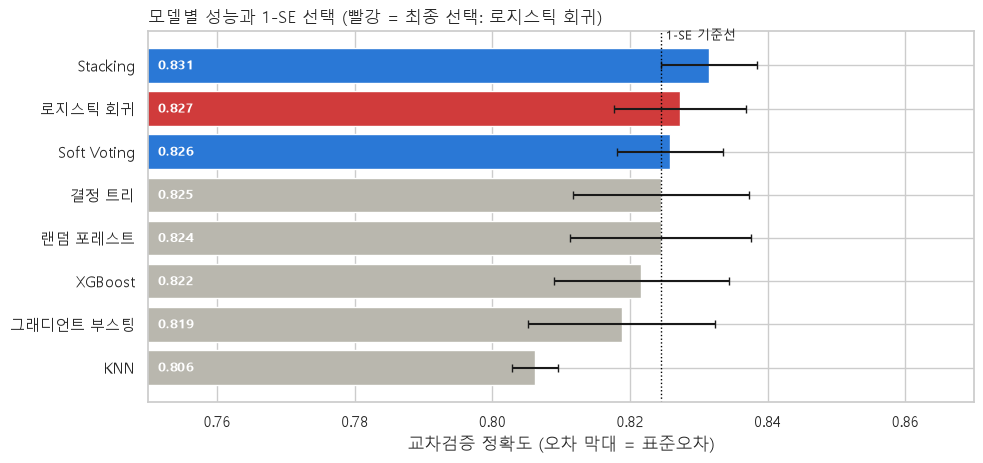

,중첩 CV,표준편차,학습-CV 차이,단순한 순서,1-SE 후보
모델,,,,,
Stacking,0.831,0.016,+0.067,8,✓
로지스틱 회귀,0.827,0.021,+0.016,1,✓
Soft Voting,0.826,0.017,+0.085,7,✓
결정 트리,0.825,0.029,+0.048,2,
랜덤 포레스트,0.824,0.029,+0.066,4,
XGBoost,0.822,0.028,+0.083,6,
그래디언트 부스팅,0.819,0.030,+0.091,5,
KNN,0.806,0.007,+0.032,3,


In [17]:
# 전체 후보 결과
all_models = {**tuned, **ensembles}  # 단일 6개 + 앙상블 2개를 한곳에서 찾기 위해
summary = pd.concat([tuned_table[["중첩 CV", "표준편차", "학습-CV 차이"]], ens_table])  # 같은 컬럼으로 합쳐 비교하기 위해
COMPLEXITY = ["로지스틱 회귀", "결정 트리", "KNN", "랜덤 포레스트", "그래디언트 부스팅", "XGBoost", "Soft Voting", "Stacking"]  # 해석 · 유지가 쉬운 순서로 단순함을 정의하기 위해
summary["단순한 순서"] = [COMPLEXITY.index(m) + 1 for m in summary.index]  # 1 = 가장 단순하도록 번호를 매기기 위해
summary = summary.sort_values("중첩 CV", ascending=False)  # 최고 점수가 맨 위에 오도록

# 1-SE 규칙
top = summary.iloc[0]  # 기준이 될 최고 점수 모델을 꺼내기 위해
cutoff = top["중첩 CV"] - top["표준편차"] / np.sqrt(cv.get_n_splits())  # 최고 점수에서 표준오차 1개를 뺀 기준선을 구하기 위해
candidates = summary[summary["중첩 CV"] >= cutoff]  # 최고와 통계적으로 구분되지 않는 후보만 남기기 위해
final_name = candidates["단순한 순서"].idxmin()  # 후보 중 가장 단순한 모델을 고르기 위해
summary["1-SE 후보"] = np.where(summary["중첩 CV"] >= cutoff, "✓", "")  # 표에서 후보를 표시하기 위해

# 모델별 성능 그래프
fig, ax = plt.subplots(figsize=(10, 4.8))  # 그래프 영역을 만들기 위해
plot = summary.iloc[::-1]  # 높은 점수가 위에 오도록 뒤집기 위해
colors = [RED if m == final_name else (BLUE if m in candidates.index else GRAY) for m in plot.index]  # 선택 · 후보 · 탈락을 색으로 구분하기 위해
ax.barh(plot.index, plot["중첩 CV"], xerr=plot["표준편차"] / np.sqrt(5), color=colors, capsize=3)  # 점수와 표준오차를 함께 보이기 위해
ax.axvline(cutoff, color="black", linestyle=":", linewidth=1)  # 1-SE 기준선을 표시하기 위해
ax.text(cutoff, len(plot) - 0.4, " 1-SE 기준선", fontsize=9)  # 기준선의 의미를 알리기 위해
for i, v in enumerate(plot["중첩 CV"]):  # 막대마다 점수를 적기 위해
    ax.text(0.7515, i, f"{v:.3f}", va="center", fontsize=9.5, color="white", fontweight="bold")  # 막대 안에 점수를 넣어 읽기 쉽게 하기 위해
ax.set_xlim(0.75, 0.87)  # 작은 차이가 보이도록 범위를 좁히기 위해
ax.set_xlabel("교차검증 정확도 (오차 막대 = 표준오차)")  # 오차 막대의 의미를 알리기 위해
ax.set_title(f"모델별 성능과 1-SE 선택 (빨강 = 최종 선택: {final_name})", loc="left")  # 최종 선택을 제목에 담기 위해
plt.tight_layout()  # 라벨이 겹치지 않도록
plt.show()  # 그래프를 출력하기 위해
summary.style.format({"중첩 CV": "{:.3f}", "표준편차": "{:.3f}", "학습-CV 차이": "{:+.3f}"})  # 전체 후보를 표로도 보이기 위해

**결과 해설**

```
Stacking 0.831          : 최고 점수, 기준선 = 0.831 - 표준오차
1-SE 후보 3개           : Stacking · 로지스틱 회귀(0.827) · Soft Voting(0.826)
최종 선택 로지스틱 회귀 : 후보 중 가장 단순 + 학습-CV 차이 +0.016으로 과적합 가장 작음
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| concat() · sort_values() · iloc[] · idxmin() | pandas | 결과 합치기 · 정렬 · 위치 선택 · 최솟값 행 | `candidates["단순한 순서"].idxmin()` |
| sqrt() · where() | numpy | 표준오차 · 조건별 표시 | `np.where(..., "✓", "")` |
| get_n_splits() | sklearn.model_selection | fold 개수 | `cv.get_n_splits()` |
| barh(xerr) · axvline() · text() · set_xlim() | matplotlib | 오차 막대 · 기준선 · 글자 · 범위 | `ax.barh(plot.index, plot["중첩 CV"], xerr=...)` |
| index() · enumerate() | Python list · 내장 함수 | 단순한 순서 번호 · 위치와 값 | `COMPLEXITY.index(m)` |
| ** (딕셔너리 합치기) · 조건 표현식 | Python 기본 문법 | 후보 묶기 · 막대 색 선택 | `{**tuned, **ensembles}` |

### 4-2. 최종 평가 데이터에서 한 번 확인

**한글 요약**

- 선택한 모델을 개발 데이터 전체로 다시 학습하고, 0-2에서 떼어 둔 **179명**으로 한 번만 평가
- 정확도 · ROC-AUC · 클래스별 정밀도 / 재현율 + 혼동행렬 · ROC 곡선

**실행 흐름**

1. **입력**: `final_name` · 개발 데이터 · 최종 평가 데이터
2. **처리**: 최종 모델 개발 데이터 전체 학습 → 179명 예측 · 생존 확률 → 지표 계산
3. **저장**: `final_model` · `hold_pred` · `hold_proba`
4. **출력**: 정확도 · ROC-AUC · 분류 보고서, 혼동행렬 · ROC 곡선

최종 모델: 로지스틱 회귀
교차검증 정확도 0.827 → 최종 평가 정확도 0.838 · ROC-AUC 0.870

              precision    recall  f1-score   support

          사망      0.852     0.891     0.871       110
          생존      0.812     0.754     0.782        69

    accuracy                          0.838       179
   macro avg      0.832     0.822     0.827       179
weighted avg      0.837     0.838     0.837       179



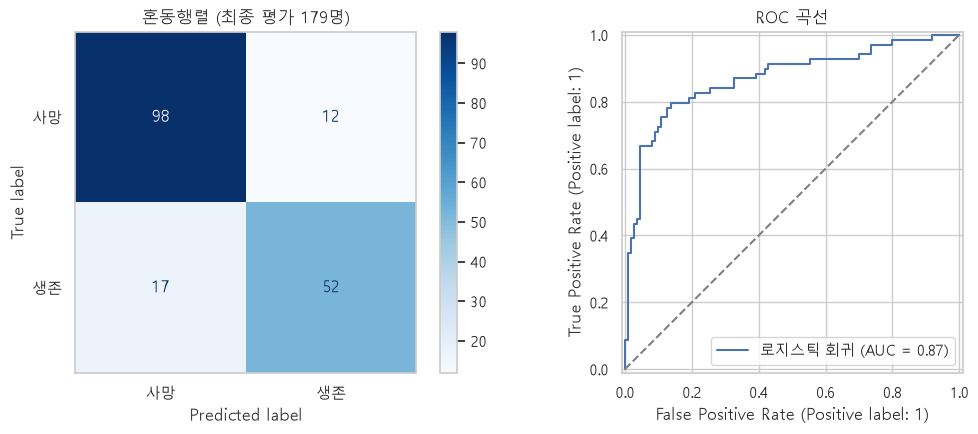

In [18]:
# 최종 학습 · 예측
final_model = clone(all_models[final_name]).fit(X_dev, y_dev)  # 개발 데이터 712명 전체로 다시 학습하기 위해
hold_pred = final_model.predict(X_hold)  # 생존 여부를 예측하기 위해
hold_proba = final_model.predict_proba(X_hold)[:, 1]  # ROC-AUC를 계산하기 위해 생존 확률도 얻음

# 평가 지표
print(f"최종 모델: {final_name}")  # 어떤 모델을 평가하는지 기록하기 위해
print(f"교차검증 정확도 {summary.loc[final_name, '중첩 CV']:.3f} → 최종 평가 정확도 {accuracy_score(y_hold, hold_pred):.3f} · ROC-AUC {roc_auc_score(y_hold, hold_proba):.3f}\n")  # 추정과 실제를 비교하기 위해
print(classification_report(y_hold, hold_pred, target_names=["사망", "생존"], digits=3))  # 클래스별 정밀도 · 재현율을 보기 위해

# 혼동행렬 · ROC 곡선
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))  # 두 평가 그래프를 나란히 보기 위해
ConfusionMatrixDisplay.from_predictions(y_hold, hold_pred, display_labels=["사망", "생존"], cmap="Blues", ax=axes[0])  # 정답 · 오답 건수를 보기 위해
axes[0].set_title("혼동행렬 (최종 평가 179명)")  # 그래프 내용을 알리기 위해
axes[0].grid(False)  # 칸 위 격자가 숫자를 가리지 않도록
RocCurveDisplay.from_predictions(y_hold, hold_proba, ax=axes[1], name=final_name)  # 모든 임계값의 성능을 보기 위해
axes[1].plot([0, 1], [0, 1], "--", color="gray")  # 무작위 추측과 비교하기 위해
axes[1].set_title("ROC 곡선")  # 그래프 내용을 알리기 위해
plt.tight_layout()  # 라벨이 겹치지 않도록
plt.show()  # 그래프를 출력하기 위해

**결과 해설**

```
교차검증 0.827 → 최종 평가 0.838 : 추정과 비슷 → 개발 데이터에 과적합되지 않음
ROC-AUC 0.870                    : 생존 · 사망 순위 구분 능력
사망 재현율 0.891                : 사망자 110명 중 약 89% 맞힘
생존 재현율 0.754                : 생존자 69명 중 약 75% 맞힘 → 놓친 생존자가 주된 오류
179명 중 1명 = 0.56%p            : 이 정도 차이는 우연 범위 안
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| clone() · fit() · predict() · predict_proba() | sklearn | 새 모델 · 학습 · 예측 · 확률 | `final_model.predict_proba(X_hold)[:, 1]` |
| accuracy_score() · roc_auc_score()<br>classification_report() | sklearn.metrics | 정확도 · ROC-AUC<br>클래스별 지표 | `accuracy_score(y_hold, hold_pred)`<br>`classification_report(..., digits=3)` |
| ConfusionMatrixDisplay · RocCurveDisplay | sklearn.metrics | 혼동행렬 · ROC 곡선 | `ConfusionMatrixDisplay.from_predictions(...)` |
| loc[] | pandas.DataFrame | 최종 모델 CV 점수 조회 | `summary.loc[final_name, '중첩 CV']` |
| [:, 1] | numpy 인덱싱 | 생존 확률 열만 | `predict_proba(X_hold)[:, 1]` |

### 4-3. 순열 중요도

**한글 요약**

- 변수 하나를 무작위로 섞었을 때 **최종 평가 정확도가 얼마나 떨어지는지**로 중요도 측정
- 30회 반복 평균 · 표준편차, 영향이 거의 없는 변수(0.001 이하)는 제외

**실행 흐름**

1. **입력**: `final_model` · 최종 평가 데이터
2. **처리**: 변수별 30회 섞기 → 정확도 감소량 평균 · 표준편차 → 영향 없는 변수 제외
3. **저장**: `imp`
4. **출력**: 순열 중요도 막대그래프

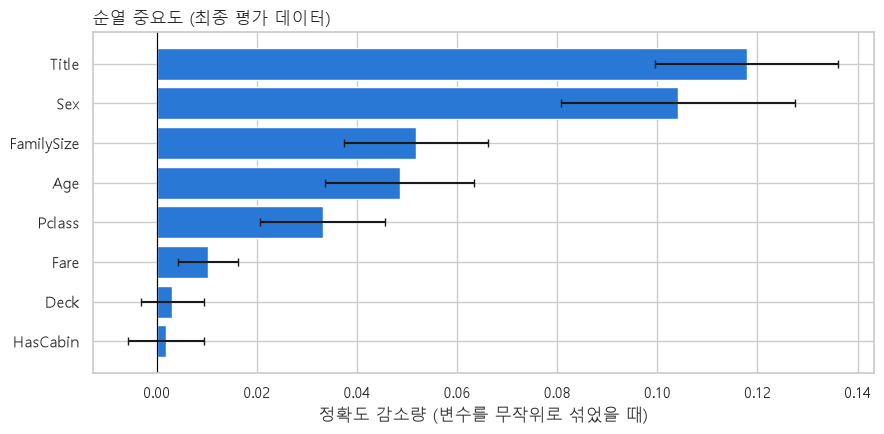

In [19]:
# 순열 중요도 계산
perm = permutation_importance(final_model, X_hold, y_hold, scoring="accuracy", n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)  # 섞는 우연을 줄이기 위해 변수별 30회 평균
imp = pd.DataFrame({"평균": perm.importances_mean, "표준편차": perm.importances_std}, index=X_hold.columns).sort_values("평균")  # 변수 이름을 붙여 정렬하기 위해
imp = imp[imp["평균"].abs() > 0.001]  # 영향이 거의 없는 변수는 그래프에서 빼기 위해

# 막대그래프
fig, ax = plt.subplots(figsize=(9, 4.5))  # 그래프 영역을 만들기 위해
ax.barh(imp.index, imp["평균"], xerr=imp["표준편차"], color=BLUE, capsize=3)  # 중요도와 흔들림을 함께 보이기 위해
ax.axvline(0, color="black", linewidth=0.8)  # 음수(섞어도 오히려 좋아짐)를 구분하기 위해
ax.set_xlabel("정확도 감소량 (변수를 무작위로 섞었을 때)")  # 중요도의 의미를 알리기 위해
ax.set_title("순열 중요도 (최종 평가 데이터)", loc="left")  # 어떤 데이터 기준인지 알리기 위해
plt.tight_layout()  # 라벨이 겹치지 않도록
plt.show()  # 그래프를 출력하기 위해

**결과 해설**

```
Title 0.118 · Sex 0.104      : 섞으면 정확도가 10%p 이상 하락 → 가장 중요
FamilySize 0.052 · Age 0.049 : 가족 규모 · 나이가 뒤를 이음
Pclass 0.033                 : 객실 등급이 그다음
Fare · Deck · HasCabin       : 0.01 이하로 영향 작음
```

- 중요도가 높다 ≠ 생존의 **원인** (예측에 많이 쓰였다는 뜻)

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| permutation_importance() | sklearn.inspection | 섞어서 성능 감소량 측정 | `permutation_importance(final_model, X_hold, y_hold, n_repeats=30, ...)` |
| DataFrame() · sort_values() · abs() | pandas | 이름 붙이기 · 정렬 · 절댓값 | `imp[imp["평균"].abs() > 0.001]` |
| barh(xerr) · axvline() | matplotlib | 오차 막대 · 0 기준선 | `ax.barh(imp.index, imp["평균"], xerr=...)` |

### 4-4. 오류 분석

**한글 요약**

- 성별 × 등급 집단별 오류율 계산 → 모델이 어떤 승객을 많이 틀리는지 확인
- 틀린 승객 중 **가장 확신하고 틀린 6명** 확인

**실행 흐름**

1. **입력**: `holdout_fe` · `hold_pred` · `hold_proba`
2. **처리**: 예측 · 확률 · 오류 여부 추가 → 성별 × 등급 오류율 → 확신도 = |확률 - 0.5| → 상위 6명
3. **저장**: `errors` · `group_error`
4. **출력**: 집단별 오류율 표, 확신하고 틀린 6명

In [20]:
# 예측 결과 붙이기
errors = holdout_fe.assign(예측=hold_pred, 생존확률=hold_proba.round(2), 오류=(hold_pred != y_hold).astype(int))  # 승객 정보 옆에 예측 · 오류를 함께 보기 위해 (1 = 틀림)

# 성별 × 등급 오류율
group_error = errors.groupby(["Sex", "Pclass"])["오류"].agg(오류율="mean", 인원="size")  # 어떤 집단을 많이 틀리는지 보기 위해
display(group_error.style.format({"오류율": "{:.0%}"}).background_gradient(subset=["오류율"], cmap="Reds"))  # 오류가 많은 집단이 진하게 보이도록

# 확신하고 틀린 승객
confident_wrong = errors[errors["오류"].eq(1)].assign(확신도=lambda d: (d["생존확률"] - 0.5).abs()).nlargest(6, "확신도")  # 0.5에서 먼 오답 = 모델이 확신하고 틀린 승객을 찾기 위해
confident_wrong[["Name", "Sex", "Pclass", "Age", "Title", "FamilySize", "Survived", "예측", "생존확률"]]  # 틀린 이유를 볼 수 있는 컬럼만 보이기 위해

,Name,Sex,Pclass,Age,Title,FamilySize,Survived,예측,생존확률
570,"Harris, Mr. George",male,2,62.0,Mr,1,1,0,0.05
297,"Allison, Miss. Helen Loraine",female,1,2.0,Miss,4,0,1,0.94
444,"Johannesen-Bratthammer, Mr. Bernt",male,3,NaN,Mr,1,1,0,0.07
146,"Andersson, Mr. August Edvard (""Wennerstrom"")",male,3,27.0,Mr,1,1,0,0.08
804,"Hedman, Mr. Oskar Arvid",male,3,27.0,Mr,1,1,0,0.08
271,"Tornquist, Mr. William Henry",male,3,25.0,Mr,1,1,0,0.09


**결과 해설**

```
여성 1 · 2등급 오류율 7% · 6% : 규칙대로 대부분 생존 → 거의 맞힘
여성 3등급 29%                : 사망한 3등급 여성을 틀림
남성 1등급 30%                : 살아남은 1등급 남성을 틀림
확신하고 틀린 6명             : 생존확률 0.05~0.09인데 생존한 남성 5명 + 0.94인데 사망한 1등급 여아 1명
```

- 모델은 **"여성 · 고등급은 생존, 남성 · 3등급은 사망"**이라는 큰 규칙을 잘 학습, 대신 그 규칙의 **예외**를 가장 많이 틀림
- 이 승객들은 현재 변수만으로는 구분할 단서가 거의 없음 → 소수 사례에 맞춘 규칙을 추가하면 과적합되므로 억지로 고치지 않음

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| assign() · groupby() · agg() · nlargest() | pandas.DataFrame | 컬럼 추가 · 집단별 오류율 · 상위 6명 | `errors.groupby(["Sex", "Pclass"])["오류"].agg(...)` |
| style.format() · background_gradient() | pandas Styler | 백분율 · 색 농도 | `.background_gradient(subset=["오류율"], cmap="Reds")` |
| eq() · abs() · round() | pandas · numpy | 오답 선택 · 절댓값 · 반올림 | `hold_proba.round(2)` |
| lambda | Python 기본 문법 | 확신도 계산 한 줄 함수 | `lambda d: (d["생존확률"] - 0.5).abs()` |

### 4-5. Kaggle 제출 파일

**한글 요약**

- Kaggle `test.csv`가 같은 폴더에 있을 때만 제출 파일 생성
- 제출용 모델은 개발 + 최종 평가 데이터 **전체 891명**으로 다시 학습

**실행 흐름**

1. **입력**: `test.csv` (있을 때만)
2. **처리**: 파일 확인 → 전체 891명 파생 변수 · 재학습 → test 파생 변수 · 예측
3. **저장**: `submission.csv` (test.csv가 있을 때)
4. **출력**: 저장 결과 또는 건너뜀 안내

In [21]:
# Kaggle 제출 파일 생성
test_path = Path("test.csv")  # 대회 파일이 있는지 확인하기 위해
if test_path.exists():  # 파일이 있을 때만 제출 파일을 만들기 위해
    full_fe = add_features(data)  # 전체 891명에 같은 파생 변수를 만들기 위해
    submit_model = clone(all_models[final_name]).fit(full_fe[X_dev.columns], full_fe["Survived"])  # 가장 많은 데이터로 재학습하기 위해
    test_fe = add_features(pd.read_csv(test_path))  # test에도 같은 변환을 적용하기 위해
    submission = pd.DataFrame({"PassengerId": test_fe["PassengerId"], "Survived": submit_model.predict(test_fe[X_dev.columns]).astype(int)})  # 제출 형식(승객 번호, 0/1)으로 만들기 위해
    submission.to_csv("submission.csv", index=False)  # Kaggle에 올릴 파일로 저장하기 위해
    print("submission.csv 저장:", submission.shape)  # 저장된 크기를 확인하기 위해
else:
    print("test.csv가 없어 제출 파일 생성을 건너뜁니다. (Kaggle Titanic 대회에서 내려받아 같은 폴더에 두면 실행됩니다)")  # 파일이 없어도 노트북이 멈추지 않도록 안내

test.csv가 없어 제출 파일 생성을 건너뜁니다. (Kaggle Titanic 대회에서 내려받아 같은 폴더에 두면 실행됩니다)


**결과 해설**

```
test.csv 없음 : 저장소에 포함하지 않아 제출 파일 생성 건너뜀
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| Path() · exists() | pathlib | 경로 · 존재 여부 | `Path("test.csv").exists()` |
| read_csv() · DataFrame() · to_csv() | pandas | test 읽기 · 제출 표 · 저장 | `submission.to_csv("submission.csv", index=False)` |
| add_features() · clone() · fit() | 사용자 정의 함수 · sklearn | 같은 변환 · 전체 재학습 | `clone(all_models[final_name]).fit(...)` |
| if · else | Python 기본 문법 | 파일 유무에 따른 분기 | `if test_path.exists():` |

---
## 5. 마무리

### 최종 결과

| 항목 | 결과 |
| :-- | :-- |
| **최종 모델** | 로지스틱 회귀 (`C=1`, 표준화 + 원-핫 인코딩, 호칭 × 등급 나이 대치) |
| **교차검증 정확도** (중첩 CV, 개발 712명) | **0.827** ± 0.021 |
| **최종 평가 정확도** (179명, 한 번만 사용) | **0.838** · ROC-AUC 0.870 |

### 핵심 결과

- **생존을 가른 요인**: 호칭 · 성별이 가장 중요 (순열 중요도 0.12 · 0.10), 가족 규모 · 나이 · 객실 등급이 뒤를 이음. 여성 74% vs 남성 19%, 1등급 여성 97% vs 3등급 남성 13%
- **복잡한 모델이 항상 이기지 않음**: 랜덤 포레스트 · XGBoost는 설정을 고르는 CV 0.84 → 중첩 CV 0.82대로 하락. Stacking(0.831) vs 로지스틱 회귀(0.827)는 표준오차 안 → 1-SE 규칙으로 가장 단순하고 과적합이 가장 작은(학습-CV 차이 +0.016) 로지스틱 회귀 선택
- **앙상블은 자동 개선이 아님**: Soft Voting이 19명을 더 맞혔지만 22명을 새로 틀려 순변화 -3명
- **일반화 확인**: 최종 평가 정확도(0.838) ≈ 교차검증 추정(0.827), 179명에서 1명 차이 = 0.56%p는 우연 범위 안

### 한계와 다음 단계

- 남은 오류는 대부분 **규칙의 예외**: 살아남은 1등급 남성(오류율 30%) · 사망한 3등급 여성(29%), 현재 변수만으로는 구분 단서 부족
- 같은 티켓을 공유한 일행의 생존 여부 같은 **그룹 단위 정보**가 다음 개선 후보 (교차검증 안에서 계산해야 누수 없음)
- Kaggle `test.csv`는 저장소에 포함하지 않아 리더보드 점수 미기록, 파일을 두면 제출 파일 생성

### 최종 요약표

| 단계 | 한 일 | 핵심 근거 |
| :-- | :-- | :-- |
| **0. 준비** | 최종 평가 179명 먼저 분리, 결측 방침 | 생존율 38.3% · 38.5%로 비율 유지 |
| **1. 피처 · 탐색** | 호칭 · 가족 · 객실 파생 변수, 집단별 생존율 · 검정 | Title V 0.573 · Sex V 0.546 |
| **2. 전처리 · 기본 모델** | 나이 대치 Pipeline, 가족 표현 · 스케일러 비교 | KNN 스케일링 없음 0.737 → 0.80 |
| **3. 튜닝 · 앙상블** | 중첩 CV, 부스팅 과적합, Voting · Stacking | RF 0.843 → 0.824, 순변화 -3명 |
| **4. 최종 평가** | 1-SE 선택 → 179명 한 번 평가, 오류 분석 | 정확도 0.838 · ROC-AUC 0.870 |